# 学習済み rank 12 の単一 bond 事後切り詰め

この Notebook は学習しない。Notebook 08 の保存済み best checkpoint を読み取り専用で復元し、内部 bond を一つずつ低い target rank へ SVD で切り詰めたときの事後感度を見る。

確認できるのは、選んだ r12 best、選んだ rank-selection validation 5,000 件、単一 bond、再学習なし、という条件だけである。

複数 bond の同時切り詰め、再学習後の回復、通常 TT との比較、非一様 rank の最適性、test 性能は、この実験の結論にしない。


## 実行スイッチ

初期値はすべて `False` である。セルを上から実行しても、checkpoint の評価や図の再生成は始まらない。

- `RUN_SETUP_AND_CONTROL`: 設定、active generation、3 閾値の best 同一性、データ分割 checksum、基準モデルの復元、4 つの `12→12` control、切り詰め候補の重み空間チェック。分類評価は基準モデルと control だけ。
- `RUN_CANDIDATE_EVALUATION`: control 通過後に、bond 2〜5 の rank 11・10・8 の 12 候補を rank-selection validation で評価し、表と図を保存する。
- `RUN_DISPLAY_SAVED`: 保存済み CSV から図を再生成して保存し、Notebook 内に表示する。モデル評価はしない。
- `RUN_PROPAGATION_DIAGNOSTIC`: bond 2 と bond 5 の 12→11 について、fc1 出力、logits、margin、予測の変化を記録する。このスイッチだけで実行でき、12 候補の分類評価は再実行しない。既存の 09 成果物は上書きしない。

`RUN_CANDIDATE_EVALUATION` は control を同じプロセスで先に通す。control に失敗した候補の loss・accuracy は保存しない。

checkpoint、データ分割、tensorization、rank、対象 bond、評価設定、許容値から決まる `run_id` が、保存済みファイルと違う場合は上書きも削除もしない。`run_id` のない旧形式も移行せず停止する。


In [13]:
import copy
import hashlib
import json
import math
import os
from pathlib import Path

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import matplotlib

from IPython.display import Image, display

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

from nn_compression.compression import TTLinear, assign_tt_linear_cores
from nn_compression.datasets import get_fashion_mnist_datasets, split_fashion_mnist_dataset
from nn_compression.metrics import relative_frobenius_error, tt_linear_structure_metrics
from nn_compression.models import MNISTMLP
from nn_compression.training import evaluate
from nn_compression.tt_mps import (
    canonicalize_tt_matrix_cores,
    merge_tt_matrix_cores,
    replace_tt_matrix_core_pair,
    split_merged_tt_matrix,
    tt_matrix_canonicality_errors,
    tt_matrix_ranks,
    tt_matrix_to_dense,
)
from nn_compression.utils import (
    atomic_write_csv,
    atomic_write_json,
    file_sha256,
    find_project_root,
    index_sha256,
    load_active_generation,
    notebook_code_sha256,
)

for font_name in ("Yu Gothic", "Meiryo", "MS Gothic"):
    if any(font_name == font.name for font in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.ioff()

RUN_SETUP_AND_CONTROL = False
RUN_CANDIDATE_EVALUATION = False
RUN_DISPLAY_SAVED = True
RUN_PROPAGATION_DIAGNOSTIC = True
IMPLEMENTATION_EXCLUDED_ASSIGNMENTS = (
    "RUN_SETUP_AND_CONTROL",
    "RUN_CANDIDATE_EVALUATION",
    "RUN_DISPLAY_SAVED",
    "RUN_PROPAGATION_DIAGNOSTIC",
)

SEED = 0
OUT_MODES = (4, 2, 2, 2, 4, 4)
IN_MODES = (2, 2, 2, 2, 7, 7)
EXPECTED_RANKS = (1, 8, 12, 12, 12, 12, 1)
BOND_INDICES = (2, 3, 4, 5)
TARGET_RANKS = (12, 11, 10, 8)
TRUNCATION_RANKS = (11, 10, 8)
SPLIT_LENGTHS = (50_000, 5_000, 5_000)
VALIDATION_BATCH_SIZE = 512
TARGET_LAYER = "fc1"
SPLIT_DIRECTION = "right"
THRESHOLD_DIRECTORY_NAMES = ("threshold_1e-06", "threshold_1e-04", "threshold_1e-02")
REPRESENTATIVE_DIRECTORY = "threshold_1e-02"
NOTEBOOK06_SPLIT_INDEX_SHA256 = (
    "aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98087503382c3372f913"
    "|12cf7fe6cc2cdbb43177107c8a30dffb86cc099386d61fa5f4f05fdb1795d360"
    "|a80ccd6c95a3aa08fcfb7a5a10ffc883344da48ec37ce605220f964cef14cb26"
)
NOTEBOOK06_IMAGE_SHA256 = "6a1fd0602db5a1066210a55375d18f9b12115269e7c6759f64504735f020d4d5"
NOTEBOOK06_LABEL_SHA256 = "6ead6f3f16028865d36fd3c8625eba751820bd8031265a3be03e206136a3c96c"
# tests/test_tt_matrix.py の float32 再構成・forward と同じ相対・絶対許容。
FLOAT32_RECONSTRUCTION_TOLERANCE = 1e-5
# notebooks/40_dmrg/10_fashion_mnist_mlp/07 の LOSS_RECHECK_ATOL。
LOSS_RECHECK_ATOL = 1e-5
# Notebook 08 の CANONICALITY_TOLERANCE。
CANONICALITY_TOLERANCE = 1e-4
FIXED_INPUT_SEED = 0
FIXED_INPUT_BATCH = 8

EXPERIMENT_NAME = "09_posthoc_single_bond_truncation_diagnostic"
NOTEBOOK08_EXPERIMENT = "08_adaptive_bond_rank_dmrg_like_pareto"

project_root = find_project_root(Path.cwd())
NOTEBOOK_PATH = (
    project_root
    / "notebooks"
    / "40_dmrg"
    / "10_fashion_mnist_mlp"
    / "09_posthoc_single_bond_truncation_diagnostic.ipynb"
)
NOTEBOOK08_MODELS = (
    project_root / "models" / "40_dmrg" / "10_fashion_mnist_mlp" / NOTEBOOK08_EXPERIMENT
)
RESULTS_DIR = project_root / "results" / "40_dmrg" / "10_fashion_mnist_mlp" / EXPERIMENT_NAME
FIGURES_DIR = RESULTS_DIR / "figures"

if RESULTS_DIR.name != EXPERIMENT_NAME or NOTEBOOK08_EXPERIMENT in str(RESULTS_DIR):
    raise RuntimeError(f"保存先が 09 専用ではありません: {RESULTS_DIR}")
print("project:", project_root)
print("results:", RESULTS_DIR)
print("RUN_SETUP_AND_CONTROL", RUN_SETUP_AND_CONTROL)
print("RUN_CANDIDATE_EVALUATION", RUN_CANDIDATE_EVALUATION)
print("RUN_DISPLAY_SAVED", RUN_DISPLAY_SAVED)
print("RUN_PROPAGATION_DIAGNOSTIC", RUN_PROPAGATION_DIAGNOSTIC)


project: D:\dev\nn-compression-svd-dmrg
results: D:\dev\nn-compression-svd-dmrg\results\40_dmrg\10_fashion_mnist_mlp\09_posthoc_single_bond_truncation_diagnostic
RUN_SETUP_AND_CONTROL False
RUN_CANDIDATE_EVALUATION False
RUN_DISPLAY_SAVED True
RUN_PROPAGATION_DIAGNOSTIC True


## bond 番号

rank 列 $(r_0, r_1, r_2, r_3, r_4, r_5, r_6)$ の内部 bond を 1 始まりで数える。bond $b$ は core $b-1$ と core $b$ の間で、rank 列の添字も $b$ である。

- bond 1: core 0 と 1 の間、rank 8。今回の `12→11・10・8` には入れない。
- bond 2: core 1 と 2 の間、rank 12。`pair_index = 1`。
- bond 3: core 2 と 3 の間、rank 12。`pair_index = 2`。
- bond 4: core 3 と 4 の間、rank 12。`pair_index = 3`。
- bond 5: core 4 と 5 の間、rank 12。`pair_index = 4`。

したがって `pair_index = bond_index - 1` である。ここを 0 始まりの bond 番号と取り違えると、別の core pair を切ることになる。


In [14]:
def pair_index_for_bond(bond_index):
    bond_index = int(bond_index)
    if bond_index not in BOND_INDICES:
        raise ValueError(f"今回の対象 bond は {BOND_INDICES} です: {bond_index}")
    pair_index = bond_index - 1
    if not 0 <= pair_index < len(OUT_MODES) - 1:
        raise ValueError(f"pair_index が core 列の外です: bond={bond_index} pair={pair_index}")
    return pair_index


def assert_bond_index_contract(ranks=EXPECTED_RANKS):
    ranks = tuple(int(rank) for rank in ranks)
    if len(ranks) != len(OUT_MODES) + 1:
        raise RuntimeError(f"rank 列の長さが mode 数 + 1 ではありません: {ranks}")
    if ranks[0] != 1 or ranks[-1] != 1:
        raise RuntimeError(f"境界 rank が 1 ではありません: {ranks}")
    if ranks[1] != 8:
        raise RuntimeError(f"bond 1 は rank 8 である必要があります: {ranks}")
    if 1 in BOND_INDICES:
        raise RuntimeError("bond 1 は今回の切り詰め対象に入っています。")
    for bond_index in BOND_INDICES:
        pair_index = pair_index_for_bond(bond_index)
        if pair_index != bond_index - 1:
            raise RuntimeError("pair_index = bond_index - 1 が崩れています。")
        if ranks[bond_index] != 12:
            raise RuntimeError(f"bond {bond_index} の基準 rank が 12 ではありません: {ranks}")
    if ranks[pair_index_for_bond(2)] != 8:
        raise RuntimeError(
            "bond 2 の pair_index は rank 列の添字 1 を指し、そこは bond 1 の rank 8 です。"
            "bond 番号と pair 番号を同じ添字にすると別の bond を切ります。"
        )
    if tuple(TARGET_RANKS) != (12, 11, 10, 8):
        raise RuntimeError(f"TARGET_RANKS が契約と違います: {TARGET_RANKS}")
    return True


assert_bond_index_contract()
print("bond contract: bond 2..5 -> pair 1..4; bond 1 rank 8 is excluded")


bond contract: bond 2..5 -> pair 1..4; bond 1 rank 8 is excluded


## 入力と復元

Notebook 08 の各閾値ディレクトリにある `active_generation.json` から世代を解決する。世代番号は書かない。3 閾値の `best_model.pt` の SHA-256 が一致することを確認し、代表として `threshold_1e-02` を読む。

復元は checkpoint の `state_dict` を `MNISTMLP` の fc1 を `TTLinear` に替えたモデルへ載せるだけである。training の resume、implementation hash の照合、optimizer は呼ばない。

データは Notebook 08 と同じ `split_fashion_mnist_dataset(..., seed=0)` と保存済み checksum で照合する。指標に使うのは rank-selection validation 5,000 件だけである。early-stopping validation で checkpoint は選ばない。train と test は指標に使わない。train 画像は checksum の照合にだけ読む。


In [15]:
def notebook06_tensor_value_sha256(tensor):
    """値の生 bytes だけをハッシュする。Notebook 06 の画像・ラベル checksum 用。

    ``nn_compression.utils.tensor_sha256`` は dtype と shape も混ぜるため、
    保存済み定数と一致しない。ここでは置き換えない。
    """
    array = tensor.detach().contiguous().cpu().numpy()
    return hashlib.sha256(array.tobytes()).hexdigest()


def current_implementation_sha256():
    return notebook_code_sha256(
        NOTEBOOK_PATH,
        excluded_assignments=IMPLEMENTATION_EXCLUDED_ASSIGNMENTS,
    )


def run_identity(checkpoint_sha256, split_index_sha256, implementation_sha256):
    """実験条件と Notebook 実装から決まる ID。時刻と絶対パスは入れない。"""
    payload = {
        "checkpoint_sha256": checkpoint_sha256,
        "split_index_sha256": split_index_sha256,
        "notebook_code_sha256": implementation_sha256,
        "out_modes": list(OUT_MODES),
        "in_modes": list(IN_MODES),
        "expected_ranks": list(EXPECTED_RANKS),
        "bond_indices": list(BOND_INDICES),
        "target_ranks": list(TARGET_RANKS),
        "split_direction": SPLIT_DIRECTION,
        "evaluation_split": "rank_selection_validation",
        "validation_batch_size": VALIDATION_BATCH_SIZE,
        "device": "cpu",
        "dtype": "float32",
        "float32_reconstruction_tolerance": FLOAT32_RECONSTRUCTION_TOLERANCE,
        "loss_recheck_atol": LOSS_RECHECK_ATOL,
        "canonicality_tolerance": CANONICALITY_TOLERANCE,
    }
    canonical = json.dumps(payload, ensure_ascii=False, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()


def stored_run_id(path):
    path = Path(path)
    if path.suffix == ".json":
        payload = json.loads(path.read_text(encoding="utf-8"))
        if not isinstance(payload, dict) or "run_id" not in payload or payload["run_id"] in ("", None):
            raise RuntimeError(
                f"{path.name} に run_id がありません。旧形式は移行せず、ファイルも変更せず停止します。"
                f" 必要なら results 配下の {RESULTS_DIR.name} を別名へ退避してから再実行してください。"
            )
        return str(payload["run_id"])
    frame = pd.read_csv(path, dtype={"run_id": str})
    if frame.empty or "run_id" not in frame.columns:
        raise RuntimeError(
            f"{path.name} に run_id 列がありません。旧形式は移行せず、ファイルも変更せず停止します。"
        )
    identifiers = {str(value) for value in frame["run_id"]}
    if len(identifiers) != 1:
        raise RuntimeError(f"{path.name} の run_id が1つではありません: {sorted(identifiers)}")
    return identifiers.pop()


SINGULAR_VALUE_FIELDS = (
    "bond_index",
    "pair_index",
    "singular_value_index",
    "singular_value",
    "run_id",
)
CANDIDATE_RESULT_FIELDS = (
    "run_id",
    "role",
    "bond_index",
    "pair_index",
    "target_rank",
    "actual_ranks",
    "singular_value_count",
    "discarded_squared_norm",
    "relative_discarded_weight",
    "sqrt_relative_discarded_weight",
    "fc1_weight_relative_frobenius_error",
    "canonicality_max_error",
    "rank_selection_validation_loss",
    "rank_selection_validation_accuracy",
    "delta_loss",
    "delta_accuracy",
    "tt_core_elements",
    "fc1_parameters",
    "total_model_parameters",
    "theoretical_fc1_macs",
    "theoretical_total_macs",
    "fixed_input_logits_relative_l2",
)


def assert_saved_run_matches(run_id, implementation_sha256):
    """書き込む前に、既存成果物の run_id と実装ハッシュを確認する。"""
    if not RESULTS_DIR.exists():
        return
    names = (
        "config.json",
        "environment.json",
        "baseline_metrics.json",
        "control_verification.json",
        "bond_singular_values.csv",
        "candidate_results.csv",
    )
    for name in names:
        path = RESULTS_DIR / name
        if not path.is_file():
            continue
        found = stored_run_id(path)
        if found != run_id:
            raise RuntimeError(
                "保存済み成果物の run_id が今回の設定または実装と違うため、上書きも削除もせず停止します: "
                f"{name} saved={found} current={run_id}"
            )
        if name != "config.json":
            continue
        payload = json.loads(path.read_text(encoding="utf-8"))
        saved_code = payload.get("notebook_code_sha256")
        if not isinstance(saved_code, str) or saved_code == "":
            raise RuntimeError(
                "config.json に notebook_code_sha256 がありません。移行も上書きもせず停止します。"
            )
        if saved_code != implementation_sha256:
            raise RuntimeError(
                "保存済みの実装ハッシュが今回の Notebook と違うため、上書きも削除もせず停止します: "
                f"saved={saved_code} current={implementation_sha256}"
            )


def resolve_notebook08_bests():
    resolved = []
    for directory_name in THRESHOLD_DIRECTORY_NAMES:
        condition = NOTEBOOK08_MODELS / directory_name / "adaptive_dmrg_like"
        active = load_active_generation(
            condition,
            pinned_files={"initial_model.pt": "initial_model_sha256"},
            required_manifest_keys=("initial_model_sha256", "rank_initial_sha256"),
        )
        if active is None:
            raise RuntimeError(
                f"active generation の pointer がありません。不完全な保存は採用しません: {condition}"
            )
        best_path = active.path / "best_model.pt"
        resolved.append(
            {
                "threshold_directory": directory_name,
                "generation": active.generation,
                "generation_directory": active.pointer["directory"],
                "best_path": best_path,
                "best_sha256": file_sha256(best_path),
            }
        )
    digests = {item["best_sha256"] for item in resolved}
    if len(digests) != 1:
        raise RuntimeError(f"3 閾値の best checkpoint が同一ではありません: {resolved}")
    representative = next(item for item in resolved if item["threshold_directory"] == REPRESENTATIVE_DIRECTORY)
    return resolved, representative


def model_from_checkpoint(path):
    payload = torch.load(path, map_location="cpu", weights_only=False)
    state = payload["state_dict"]
    cores = [state[f"fc1.cores.{index}"] for index in range(len(OUT_MODES))]
    model = MNISTMLP()
    model.fc1 = TTLinear(cores, OUT_MODES, IN_MODES, bias=state["fc1.bias"])
    model.load_state_dict(state)
    model.to(torch.device("cpu"))
    return model, payload


def actual_ranks_of(model):
    return tuple(int(rank) for rank in tt_matrix_ranks(list(model.fc1.cores)))


def dense_fc1_weight(model):
    cores = [core.detach() for core in model.fc1.cores]
    return tt_matrix_to_dense(cores, OUT_MODES, IN_MODES)


def clone_state(model):
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}


def states_equal(left, right):
    if set(left) != set(right):
        return False
    return all(torch.equal(left[key], right[key]) for key in left)


def make_loader(dataset):
    return DataLoader(
        dataset,
        batch_size=VALIDATION_BATCH_SIZE,
        shuffle=False,
        drop_last=False,
        num_workers=0,
        pin_memory=False,
    )


def evaluate_rank_selection(model, dataset):
    criterion = nn.CrossEntropyLoss(reduction="mean")
    loss, accuracy = evaluate(model, make_loader(dataset), criterion, torch.device("cpu"))
    return float(loss), float(accuracy)


def load_rank_selection_split():
    full_train, test_dataset = get_fashion_mnist_datasets(project_root / "data", download=False)
    train_dataset, early_dataset, rank_dataset = split_fashion_mnist_dataset(
        full_train, SPLIT_LENGTHS, seed=SEED
    )
    if (len(train_dataset), len(early_dataset), len(rank_dataset)) != SPLIT_LENGTHS:
        raise RuntimeError("分割サイズが 50,000 / 5,000 / 5,000 ではありません。")
    if len(test_dataset) != 10_000:
        raise RuntimeError("test の長さが 10,000 ではありません。中身は使いません。")
    del test_dataset
    train_images = torch.stack([train_dataset[index][0] for index in range(len(train_dataset))])
    train_labels = torch.tensor(
        [int(train_dataset[index][1]) for index in range(len(train_dataset))],
        dtype=torch.int64,
    )
    image_sha = notebook06_tensor_value_sha256(train_images)
    label_sha = notebook06_tensor_value_sha256(train_labels)
    split_sha = "|".join(index_sha256(subset) for subset in (train_dataset, early_dataset, rank_dataset))
    del train_images, train_labels, train_dataset, early_dataset
    if (
        image_sha != NOTEBOOK06_IMAGE_SHA256
        or label_sha != NOTEBOOK06_LABEL_SHA256
        or split_sha != NOTEBOOK06_SPLIT_INDEX_SHA256
    ):
        raise RuntimeError("データ分割または画像 checksum が Notebook 08 の記録と一致しません。")
    return rank_dataset, split_sha


def fixed_logits_input():
    generator = torch.Generator().manual_seed(FIXED_INPUT_SEED)
    return torch.randn(FIXED_INPUT_BATCH, 1, 28, 28, generator=generator)


def environment_record():
    return {
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "gpu_name": "",
        "device": "cpu",
        "compile": False,
        "execution": "eager",
        "training": False,
    }


## 単一 bond の作り方

各候補は、元の r12 best の独立コピーから作る。切り詰めは累積しない。

1. 対象 pair の左 site を中心に、既存の `canonicalize_tt_matrix_cores` で正準化する。中心より左は left-canonical、中心より右は right-canonical になる。
2. 対象の隣接 2 core だけを `merge_tt_matrix_cores` で結合する。
3. `split_merged_tt_matrix(..., max_bond=target_rank, direction="right")` で分割する。方向は全条件で右向きに固定する。
4. `replace_tt_matrix_core_pair` と `assign_tt_linear_cores` で、その pair だけをモジュールへ戻す。

正準化は gauge 変換なので、対象外の core の数値も変わり得る。変えないのは対象以外の bond rank、fc1 bias、fc2、fc3 である。`12→12` では、この gauge のあと全特異値を残すので、fc1 の実効 weight は再構成許容の範囲で元と一致する必要がある。

特異値を $\sigma_{b,j}$ とすると、target rank $r$ の relative discarded weight は

$$
d_b(r)
=
\frac{\sum_{j>r}\sigma_{b,j}^{2}}{\sum_j\sigma_{b,j}^{2}}
$$

である。$\sum_{j>r}\sigma_{b,j}^{2}$ を discarded squared norm、$\sqrt{d_b(r)}$ を relative Frobenius error の理論値として別に保存する。正準条件の下では、単一 bond の切り詰めについて

$$
\frac{\lVert W-\widetilde W\rVert_F}{\lVert W\rVert_F}
\approx
\sqrt{d_b(r)}
$$

が成り立つことを、float32 再構成と同じ許容 $10^{-5}$ で確認する。この比は分類 loss や accuracy の保証ではない。

差分の符号は、候補から基準を引く。

$$
\Delta\mathrm{loss}=\mathrm{loss}_{\mathrm{truncated}}-\mathrm{loss}_{\mathrm{baseline}}
$$

$$
\Delta\mathrm{accuracy}=\mathrm{accuracy}_{\mathrm{truncated}}-\mathrm{accuracy}_{\mathrm{baseline}}
$$

accuracy は割合のまま保存する。percentage points へは図の表示時だけ換算する。


In [16]:
def structure_of(model):
    metrics = tt_linear_structure_metrics(model, TARGET_LAYER)
    return {
        "actual_ranks": tuple(int(rank) for rank in metrics.actual_ranks),
        "tt_core_elements": int(metrics.tt_core_elements),
        "fc1_parameters": int(metrics.layer_parameters),
        "total_model_parameters": int(metrics.total_parameters),
        "theoretical_fc1_macs": int(metrics.layer_macs),
        "theoretical_total_macs": int(metrics.total_macs),
    }


def canonicality_max_error(cores, center):
    errors = tt_matrix_canonicality_errors(cores, OUT_MODES, IN_MODES, int(center))
    values = [float(value.detach()) for value in errors["left"] + errors["right"]]
    if not values or not all(math.isfinite(value) for value in values):
        raise RuntimeError(f"正準誤差が有限ではありません: center={center}")
    return max(values)


def discarded_from_split(split):
    values = split.singular_values.detach().to(dtype=torch.float64)
    if values.ndim != 1 or int(values.shape[0]) < 1 or not torch.isfinite(values).all():
        raise RuntimeError("SVD の特異値が有限な 1 階列ではありません。")
    retained = int(split.retained_rank)
    scale = values.max()
    squares = (values / scale).square()
    total = squares.sum()
    tail = squares[retained:].sum()
    if not torch.isfinite(total) or float(total) <= 0.0 or not torch.isfinite(tail):
        raise RuntimeError("discarded weight の分母または tail が有限な正の値ではありません。")
    relative = float(tail / total)
    direct_tail = values[retained:].square().sum()
    api_tail = split.discarded_squared_norm.detach().to(dtype=torch.float64)
    torch.testing.assert_close(api_tail, direct_tail, rtol=FLOAT32_RECONSTRUCTION_TOLERANCE, atol=FLOAT32_RECONSTRUCTION_TOLERANCE)
    return {
        "singular_values": [float(value) for value in values],
        "singular_value_count": int(values.shape[0]),
        "discarded_squared_norm": float(direct_tail),
        "relative_discarded_weight": relative,
        "sqrt_relative_discarded_weight": math.sqrt(relative),
    }


def assert_parameters_finite(model):
    for name, parameter in model.named_parameters():
        if not torch.isfinite(parameter.detach()).all():
            raise RuntimeError(f"parameter が有限ではありません: {name}")


def assert_outside_parameters_unchanged(candidate, original_state):
    for name, value in candidate.state_dict().items():
        if name.startswith("fc1.cores"):
            continue
        if not torch.equal(value.detach().cpu(), original_state[name]):
            raise RuntimeError(f"対象外 parameter が変化しました: {name}")


def build_single_bond(model, bond_index, target_rank):
    pair_index = pair_index_for_bond(bond_index)
    candidate = copy.deepcopy(model)
    cores = [core.detach() for core in candidate.fc1.cores]
    canonical = canonicalize_tt_matrix_cores(cores, OUT_MODES, IN_MODES, pair_index)
    merged = merge_tt_matrix_cores(canonical[pair_index], canonical[pair_index + 1])
    split = split_merged_tt_matrix(merged, max_bond=int(target_rank), direction=SPLIT_DIRECTION)
    if int(split.retained_rank) != int(target_rank):
        raise RuntimeError(
            f"target rank と SVD の retained rank が一致しません: "
            f"bond={bond_index} target={target_rank} retained={split.retained_rank}"
        )
    replaced = replace_tt_matrix_core_pair(
        canonical, pair_index, split.left_core, split.right_core
    )
    assign_tt_linear_cores(candidate.fc1, replaced, requires_grad=None)
    ranks = actual_ranks_of(candidate)
    expected = list(EXPECTED_RANKS)
    expected[bond_index] = int(target_rank)
    if ranks != tuple(expected):
        raise RuntimeError(f"actual ranks が対象 bond 以外も変化しました: {ranks} expected={tuple(expected)}")
    if int(candidate.fc1.cores[pair_index].shape[3]) != int(target_rank):
        raise RuntimeError("pair の左 core の右 bond が target rank ではありません。")
    if int(candidate.fc1.cores[pair_index + 1].shape[0]) != int(target_rank):
        raise RuntimeError("pair の右 core の左 bond が target rank ではありません。")
    assert_parameters_finite(candidate)
    canonicality = canonicality_max_error(
        [core.detach() for core in candidate.fc1.cores],
        pair_index + 1,
    )
    if canonicality > CANONICALITY_TOLERANCE:
        raise RuntimeError(
            f"正準誤差が Notebook 08 の許容を超えています: bond={bond_index} error={canonicality}"
        )
    return candidate, split, canonicality


def relative_weight_error(reference_weight, candidate):
    error = relative_frobenius_error(reference_weight, dense_fc1_weight(candidate)).detach()
    if not torch.isfinite(error):
        raise RuntimeError("fc1 の relative Frobenius error が有限ではありません。")
    return float(error)


def assert_discarded_matches_weight(relative_error, sqrt_discarded):
    torch.testing.assert_close(
        torch.tensor(relative_error, dtype=torch.float64),
        torch.tensor(sqrt_discarded, dtype=torch.float64),
        rtol=FLOAT32_RECONSTRUCTION_TOLERANCE,
        atol=FLOAT32_RECONSTRUCTION_TOLERANCE,
    )


def logit_relative_error(candidate, baseline_logits, images):
    with torch.no_grad():
        logits = candidate(images)
    error = torch.linalg.vector_norm(logits - baseline_logits) / torch.linalg.vector_norm(baseline_logits)
    return float(error.detach())


def metric_row(model, bond_index, target_rank, discarded, canonicality, role, reference_weight):
    structure = structure_of(model)
    relative_error = relative_weight_error(reference_weight, model)
    assert_discarded_matches_weight(relative_error, discarded["sqrt_relative_discarded_weight"])
    return {
        "role": role,
        "bond_index": bond_index,
        "pair_index": pair_index_for_bond(bond_index),
        "target_rank": int(target_rank),
        "actual_ranks": "|".join(str(rank) for rank in structure["actual_ranks"]),
        "singular_value_count": discarded["singular_value_count"],
        "discarded_squared_norm": discarded["discarded_squared_norm"],
        "relative_discarded_weight": discarded["relative_discarded_weight"],
        "sqrt_relative_discarded_weight": discarded["sqrt_relative_discarded_weight"],
        "fc1_weight_relative_frobenius_error": relative_error,
        "canonicality_max_error": canonicality,
        "tt_core_elements": structure["tt_core_elements"],
        "fc1_parameters": structure["fc1_parameters"],
        "total_model_parameters": structure["total_model_parameters"],
        "theoretical_fc1_macs": structure["theoretical_fc1_macs"],
        "theoretical_total_macs": structure["theoretical_total_macs"],
    }


## control と候補評価

`12→12` は研究候補ではなく、正準化と再分割が実効 weight を保つかの control である。次をすべて満たさない場合は、rank 11・10・8 の分類結果を解釈せず、表にも保存しない。

- fc1 実効 weight が float32 再構成許容 $10^{-5}$ で一致する。
- 固定入力の logits の相対 L2 誤差が、同じ $10^{-5}$ 以下である。要素ごとの絶対差は float32 の丸めで $1.9\times 10^{-5}$ まで出るため、要素判定ではなくベクトル相対誤差を使う。
- rank-selection validation の loss 差が Notebook 07 の `LOSS_RECHECK_ATOL = 1e-5` 以下で、accuracy は基準モデルと一致する。
- actual rank、対象外 parameter、正準誤差、有限性が契約を満たす。

費用は `tt_linear_structure_metrics` の TT core 要素数、層 parameter 数、モデル parameter 数、直接縮約の理論 MACs である。MACs は 1 sample あたりの積和回数で、bias と活性化は含まない。


In [17]:
def assert_control_weight_and_logits(candidate, reference_weight, baseline_logits, images):
    torch.testing.assert_close(
        dense_fc1_weight(candidate),
        reference_weight,
        rtol=FLOAT32_RECONSTRUCTION_TOLERANCE,
        atol=FLOAT32_RECONSTRUCTION_TOLERANCE,
    )
    relative_logits = logit_relative_error(candidate, baseline_logits, images)
    if relative_logits > FLOAT32_RECONSTRUCTION_TOLERANCE:
        raise RuntimeError(f"control の logits 相対誤差が許容を超えています: {relative_logits}")
    return relative_logits


def require_evaluation_metrics(loss, accuracy, baseline_loss, baseline_accuracy, *, bond_index, target_rank):
    """評価直後に有限性と accuracy の範囲を確認する。不正値は置換しない。"""
    if not math.isfinite(loss):
        raise RuntimeError(
            f"loss が有限ではありません: bond={bond_index} target_rank={target_rank} loss={loss!r}"
        )
    if not math.isfinite(accuracy) or accuracy < 0.0 or accuracy > 1.0:
        raise RuntimeError(
            "accuracy が 0 以上 1 以下の有限値ではありません: "
            f"bond={bond_index} target_rank={target_rank} accuracy={accuracy!r}"
        )
    delta_loss = loss - baseline_loss
    delta_accuracy = accuracy - baseline_accuracy
    if not math.isfinite(delta_loss) or not math.isfinite(delta_accuracy):
        raise RuntimeError(
            "delta_loss または delta_accuracy が有限ではありません: "
            f"bond={bond_index} target_rank={target_rank} "
            f"delta_loss={delta_loss!r} delta_accuracy={delta_accuracy!r}"
        )
    return delta_loss, delta_accuracy


def run_setup_and_control():
    resolved, representative = resolve_notebook08_bests()
    checkpoint_sha_before = representative["best_sha256"]
    rank_dataset, split_sha = load_rank_selection_split()
    model, payload = model_from_checkpoint(representative["best_path"])
    if not isinstance(model.fc1, TTLinear) or len(model.fc1.cores) != 6:
        raise RuntimeError("対象層が 6-core TTLinear ではありません。")
    if tuple(model.fc1.out_modes) != OUT_MODES or tuple(model.fc1.in_modes) != IN_MODES:
        raise RuntimeError("復元モデルの mode が契約と違います。")
    if list(payload["out_modes"]) != list(OUT_MODES) or list(payload["in_modes"]) != list(IN_MODES):
        raise RuntimeError("checkpoint の tensorization が契約と違います。")
    ranks = actual_ranks_of(model)
    assert_bond_index_contract(ranks)
    if ranks != EXPECTED_RANKS or list(payload["actual_ranks"]) != list(EXPECTED_RANKS):
        raise RuntimeError(f"actual ranks が {EXPECTED_RANKS} ではありません: {ranks}")
    assert_parameters_finite(model)
    for bond_index in BOND_INDICES:
        pair_index = pair_index_for_bond(bond_index)
        if int(model.fc1.cores[pair_index].shape[3]) != ranks[bond_index]:
            raise RuntimeError("bond 番号と core shape の対応がずれています。")
    structure = structure_of(model)
    if (
        structure["tt_core_elements"] != int(payload["tt_core_elements"])
        or structure["fc1_parameters"] != int(payload["fc1_parameters"])
        or structure["total_model_parameters"] != int(payload["total_parameters"])
        or structure["theoretical_fc1_macs"] != int(payload["theoretical_fc1_macs"])
        or structure["theoretical_total_macs"] != int(payload["theoretical_total_macs"])
    ):
        raise RuntimeError("構造指標が checkpoint の記録と一致しません。")
    original_state = clone_state(model)
    reference_weight = dense_fc1_weight(model)
    images = fixed_logits_input()
    with torch.no_grad():
        baseline_logits = model(images)
    baseline_loss, baseline_accuracy = evaluate_rank_selection(model, rank_dataset)
    require_evaluation_metrics(
        baseline_loss,
        baseline_accuracy,
        baseline_loss,
        baseline_accuracy,
        bond_index="baseline",
        target_rank=12,
    )
    implementation_sha256 = current_implementation_sha256()
    run_id = run_identity(checkpoint_sha_before, split_sha, implementation_sha256)

    controls = []
    singular_rows = []
    for bond_index in BOND_INDICES:
        candidate, split, canonicality = build_single_bond(model, bond_index, 12)
        assert_outside_parameters_unchanged(candidate, original_state)
        if actual_ranks_of(candidate) != EXPECTED_RANKS:
            raise RuntimeError("12→12 control の rank 列が元モデルと違います。")
        discarded = discarded_from_split(split)
        for index, value in enumerate(discarded["singular_values"], start=1):
            singular_rows.append(
                {
                    "bond_index": bond_index,
                    "pair_index": pair_index_for_bond(bond_index),
                    "singular_value_index": index,
                    "singular_value": value,
                    "run_id": run_id,
                }
            )
        relative_logits = assert_control_weight_and_logits(
            candidate, reference_weight, baseline_logits, images
        )
        loss, accuracy = evaluate_rank_selection(candidate, rank_dataset)
        delta_loss, delta_accuracy = require_evaluation_metrics(
            loss,
            accuracy,
            baseline_loss,
            baseline_accuracy,
            bond_index=bond_index,
            target_rank=12,
        )
        if abs(loss - baseline_loss) > LOSS_RECHECK_ATOL or accuracy != baseline_accuracy:
            raise RuntimeError(
                "12→12 control の rank-selection 指標が基準と一致しません: "
                f"bond={bond_index} loss={loss} accuracy={accuracy}"
            )
        row = metric_row(candidate, bond_index, 12, discarded, canonicality, "control", reference_weight)
        row.update(
            {
                "rank_selection_validation_loss": loss,
                "rank_selection_validation_accuracy": accuracy,
                "delta_loss": delta_loss,
                "delta_accuracy": delta_accuracy,
                "fixed_input_logits_relative_l2": relative_logits,
            }
        )
        row["run_id"] = run_id
        controls.append(row)
        del candidate

    weight_checks = []
    for bond_index in BOND_INDICES:
        for target_rank in TRUNCATION_RANKS:
            candidate, split, canonicality = build_single_bond(model, bond_index, target_rank)
            assert_outside_parameters_unchanged(candidate, original_state)
            discarded = discarded_from_split(split)
            row = metric_row(
                candidate,
                bond_index,
                target_rank,
                discarded,
                canonicality,
                "truncation",
                reference_weight,
            )
            row["run_id"] = run_id
            weight_checks.append(row)
            del candidate
    if not states_equal(clone_state(model), original_state):
        raise RuntimeError("診断中に元モデルが変化しました。")
    if file_sha256(representative["best_path"]) != checkpoint_sha_before:
        raise RuntimeError("診断中に checkpoint ファイルが変化しました。")

    assert_saved_run_matches(run_id, implementation_sha256)
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    config = {
        "run_id": run_id,
        "notebook_code_sha256": implementation_sha256,
        "experiment": EXPERIMENT_NAME,
        "training": False,
        "representative_threshold_directory": REPRESENTATIVE_DIRECTORY,
        "checkpoint_sha256": checkpoint_sha_before,
        "thresholds": [
            {
                "threshold_directory": item["threshold_directory"],
                "generation": item["generation"],
                "generation_directory": item["generation_directory"],
                "best_sha256": item["best_sha256"],
            }
            for item in resolved
        ],
        "out_modes": list(OUT_MODES),
        "in_modes": list(IN_MODES),
        "expected_ranks": list(EXPECTED_RANKS),
        "bond_indices": list(BOND_INDICES),
        "pair_index_rule": "bond_index - 1",
        "target_ranks": list(TARGET_RANKS),
        "split_direction": SPLIT_DIRECTION,
        "split_index_sha256": split_sha,
        "evaluation_split": "rank_selection_validation",
        "evaluation_samples": len(rank_dataset),
        "validation_batch_size": VALIDATION_BATCH_SIZE,
        "criterion": "mean_cross_entropy",
        "device": "cpu",
        "float32_reconstruction_tolerance": FLOAT32_RECONSTRUCTION_TOLERANCE,
        "loss_recheck_atol": LOSS_RECHECK_ATOL,
        "canonicality_tolerance": CANONICALITY_TOLERANCE,
        "results_dir": str(RESULTS_DIR.relative_to(project_root)).replace("\\", "/"),
    }
    baseline = {
        "run_id": run_id,
        "role": "baseline",
        "checkpoint_sha256": checkpoint_sha_before,
        "actual_ranks": list(ranks),
        "rank_selection_validation_loss": baseline_loss,
        "rank_selection_validation_accuracy": baseline_accuracy,
        "evaluation_samples": len(rank_dataset),
        **{key: structure[key] for key in structure if key != "actual_ranks"},
    }
    atomic_write_json(RESULTS_DIR / "config.json", config)
    environment = environment_record()
    environment["run_id"] = run_id
    atomic_write_json(RESULTS_DIR / "environment.json", environment)
    atomic_write_json(RESULTS_DIR / "baseline_metrics.json", baseline)
    atomic_write_json(
        RESULTS_DIR / "control_verification.json",
        {
            "run_id": run_id,
            "passed": True,
            "controls": controls,
            "truncation_weight_checks": weight_checks,
            "original_model_unchanged": True,
            "checkpoint_unchanged": True,
        },
    )
    atomic_write_csv(RESULTS_DIR / "bond_singular_values.csv", singular_rows, SINGULAR_VALUE_FIELDS)
    print("control passed:", len(controls))
    print("baseline loss", baseline_loss, "accuracy", baseline_accuracy)
    print("singular values", len(singular_rows))
    return {
        "model": model,
        "original_state": original_state,
        "reference_weight": reference_weight,
        "rank_dataset": rank_dataset,
        "baseline_loss": baseline_loss,
        "baseline_accuracy": baseline_accuracy,
        "baseline_row": baseline,
        "controls": controls,
        "structure": structure,
        "run_id": run_id,
        "implementation_sha256": implementation_sha256,
    }


def run_candidate_evaluation(prepared):
    if not (RESULTS_DIR / "control_verification.json").is_file():
        raise RuntimeError("control の検証結果が無いため、切り詰め候補は評価しません。")
    saved = json.loads((RESULTS_DIR / "control_verification.json").read_text(encoding="utf-8"))
    if saved.get("passed") is not True:
        raise RuntimeError("control が通過していないため、切り詰め候補は評価しません。")
    if saved.get("run_id") != prepared["run_id"]:
        raise RuntimeError(
            "control の run_id が今回の設定と違うため、候補結果は保存しません: "
            f"saved={saved.get('run_id')!r} current={prepared['run_id']!r}"
        )
    assert_saved_run_matches(prepared["run_id"], prepared["implementation_sha256"])
    rows = []
    baseline = prepared["baseline_row"]
    rows.append(
        {
            "run_id": prepared["run_id"],
            "role": "baseline",
            "bond_index": "",
            "pair_index": "",
            "target_rank": 12,
            "actual_ranks": "|".join(str(rank) for rank in baseline["actual_ranks"]),
            "singular_value_count": "",
            "discarded_squared_norm": 0.0,
            "relative_discarded_weight": 0.0,
            "sqrt_relative_discarded_weight": 0.0,
            "fc1_weight_relative_frobenius_error": 0.0,
            "canonicality_max_error": "",
            "rank_selection_validation_loss": prepared["baseline_loss"],
            "rank_selection_validation_accuracy": prepared["baseline_accuracy"],
            "delta_loss": 0.0,
            "delta_accuracy": 0.0,
            "tt_core_elements": baseline["tt_core_elements"],
            "fc1_parameters": baseline["fc1_parameters"],
            "total_model_parameters": baseline["total_model_parameters"],
            "theoretical_fc1_macs": baseline["theoretical_fc1_macs"],
            "theoretical_total_macs": baseline["theoretical_total_macs"],
        }
    )
    for control in prepared["controls"]:
        rows.append(control)
    for bond_index in BOND_INDICES:
        for target_rank in TRUNCATION_RANKS:
            candidate, split, canonicality = build_single_bond(
                prepared["model"], bond_index, target_rank
            )
            assert_outside_parameters_unchanged(candidate, prepared["original_state"])
            discarded = discarded_from_split(split)
            row = metric_row(
                candidate,
                bond_index,
                target_rank,
                discarded,
                canonicality,
                "truncation",
                prepared["reference_weight"],
            )
            loss, accuracy = evaluate_rank_selection(candidate, prepared["rank_dataset"])
            delta_loss, delta_accuracy = require_evaluation_metrics(
                loss,
                accuracy,
                prepared["baseline_loss"],
                prepared["baseline_accuracy"],
                bond_index=bond_index,
                target_rank=target_rank,
            )
            row.update(
                {
                    "run_id": prepared["run_id"],
                    "rank_selection_validation_loss": loss,
                    "rank_selection_validation_accuracy": accuracy,
                    "delta_loss": delta_loss,
                    "delta_accuracy": delta_accuracy,
                }
            )
            rows.append(row)
            del candidate
    if not states_equal(clone_state(prepared["model"]), prepared["original_state"]):
        raise RuntimeError("候補評価のあとで元モデルが変化しました。")
    for row in rows:
        require_evaluation_metrics(
            float(row["rank_selection_validation_loss"]),
            float(row["rank_selection_validation_accuracy"]),
            prepared["baseline_loss"],
            prepared["baseline_accuracy"],
            bond_index=row["bond_index"] if row["bond_index"] != "" else "baseline",
            target_rank=row["target_rank"],
        )
        if row.get("run_id") != prepared["run_id"]:
            raise RuntimeError("候補結果の行に今回の run_id がありません。CSV は保存しません。")
    atomic_write_csv(RESULTS_DIR / "candidate_results.csv", rows, CANDIDATE_RESULT_FIELDS)
    print("candidate rows", len(rows))
    return rows


def assert_display_run_ids(frame):
    sources = (
        "config.json",
        "baseline_metrics.json",
        "control_verification.json",
    )
    identifiers = {}
    for name in sources:
        path = RESULTS_DIR / name
        if not path.is_file():
            raise RuntimeError(f"{name} が無いため、図は再生成も保存もしません。")
        identifiers[name] = stored_run_id(path)
    if len(set(identifiers.values())) != 1:
        raise RuntimeError(
            "config、baseline、control の run_id が一致しないため、図は保存しません: "
            + ", ".join(f"{name}={value}" for name, value in identifiers.items())
        )
    if "run_id" not in frame.columns:
        raise RuntimeError("candidate_results.csv に run_id 列がありません。図は保存しません。")
    row_ids = {str(value) for value in frame["run_id"]}
    expected = next(iter(set(identifiers.values())))
    if row_ids != {expected}:
        raise RuntimeError(
            "CSV の全行が単一 run_id でないか、config と一致しないため、図は保存しません: "
            f"csv={sorted(row_ids)} config={expected}"
        )
    config = json.loads((RESULTS_DIR / "config.json").read_text(encoding="utf-8"))
    for key in ("checkpoint_sha256", "split_index_sha256", "run_id", "notebook_code_sha256"):
        if key not in config or config[key] in ("", None):
            raise RuntimeError(f"config.json に {key} がありません。図は保存しません。")
    current_code = current_implementation_sha256()
    if config["notebook_code_sha256"] != current_code:
        raise RuntimeError("Notebook の実装ハッシュが保存済み config と違うため、図は保存しません。")
    current_run = run_identity(config["checkpoint_sha256"], config["split_index_sha256"], current_code)
    if config["run_id"] != current_run or expected != current_run:
        raise RuntimeError("保存済み run_id が現在の Notebook と設定から再計算した値と違うため、図は保存しません。")


def save_and_show(figure, path):
    figure.savefig(path, dpi=150)
    plt.close(figure)
    display(Image(filename=str(path)))


def display_saved_results():
    path = RESULTS_DIR / "candidate_results.csv"
    if not path.is_file():
        print("candidate_results.csv が無いため、切り詰め候補の図は表示しません。")
        return
    frame = pd.read_csv(path, dtype={"run_id": str})
    assert_display_run_ids(frame)
    frame["bond_index"] = pd.to_numeric(frame["bond_index"], errors="coerce")
    frame["target_rank"] = pd.to_numeric(frame["target_rank"])
    truncations = frame[frame["role"] == "truncation"].copy()
    baseline = frame[frame["role"] == "baseline"]
    if truncations.empty or baseline.empty:
        raise RuntimeError("図に必要な baseline または切り詰め候補が csv にありません。")
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    bonds = sorted(int(value) for value in truncations["bond_index"].unique())

    figure, axis = plt.subplots(figsize=(7.2, 4.4))
    for bond_index in bonds:
        subset = frame[(frame["bond_index"] == bond_index) & (frame["role"].isin(["control", "truncation"]))]
        subset = subset.sort_values("target_rank")
        axis.plot(
            subset["target_rank"],
            subset["relative_discarded_weight"],
            marker="o",
            label=f"bond {bond_index}",
        )
    axis.set_xlabel("target rank")
    axis.set_ylabel("relative discarded weight (dimensionless)")
    axis.set_title("Single-bond relative discarded weight")
    axis.legend()
    figure.tight_layout()
    save_and_show(figure, FIGURES_DIR / "01_relative_discarded_weight_by_bond.png")

    figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
    for bond_index in bonds:
        subset = truncations[truncations["bond_index"] == bond_index].sort_values("target_rank")
        axes[0].plot(subset["target_rank"], subset["delta_loss"], marker="o", label=f"bond {bond_index}")
        axes[1].plot(
            subset["target_rank"],
            subset["delta_accuracy"] * 100.0,
            marker="o",
            label=f"bond {bond_index}",
        )
    axes[0].axhline(0.0, color="black", linewidth=1.0, label="r12 baseline")
    axes[1].axhline(0.0, color="black", linewidth=1.0, label="r12 baseline")
    axes[0].set_xlabel("target rank")
    axes[1].set_xlabel("target rank")
    axes[0].set_ylabel("validation loss change (dimensionless)")
    axes[1].set_ylabel("validation accuracy change (percentage points)")
    axes[0].set_title("Delta validation loss")
    axes[1].set_title("Delta validation accuracy")
    axes[0].legend()
    axes[1].legend()
    figure.tight_layout()
    save_and_show(figure, FIGURES_DIR / "02_validation_deltas_by_bond.png")

    figure, axes = plt.subplots(1, 2, figsize=(12.4, 5.4))
    for bond_index in bonds:
        subset = truncations[truncations["bond_index"] == bond_index]
        axes[0].scatter(
            subset["total_model_parameters"],
            subset["rank_selection_validation_accuracy"],
            label=f"bond {int(bond_index)}",
        )
        axes[1].scatter(
            subset["theoretical_total_macs"],
            subset["rank_selection_validation_accuracy"],
        )
        for _, point in subset.iterrows():
            rank_label = str(int(point["target_rank"]))
            axes[0].annotate(
                rank_label,
                (point["total_model_parameters"], point["rank_selection_validation_accuracy"]),
                textcoords="offset points",
                xytext=(5, 4),
                fontsize=8,
            )
            axes[1].annotate(
                rank_label,
                (point["theoretical_total_macs"], point["rank_selection_validation_accuracy"]),
                textcoords="offset points",
                xytext=(5, 4),
                fontsize=8,
            )
    base_accuracy = float(baseline["rank_selection_validation_accuracy"].iloc[0])
    axes[0].scatter(
        [float(baseline["total_model_parameters"].iloc[0])],
        [base_accuracy],
        marker="*",
        s=180,
        c="black",
        label="r12 baseline",
        zorder=3,
    )
    axes[1].scatter(
        [float(baseline["theoretical_total_macs"].iloc[0])],
        [base_accuracy],
        marker="*",
        s=180,
        c="black",
        zorder=3,
    )
    axes[0].set_xlabel("total model parameter count")
    axes[1].set_xlabel("theoretical total model MACs per sample")
    axes[0].set_ylabel("rank-selection validation accuracy (fraction)")
    axes[1].set_ylabel("rank-selection validation accuracy (fraction)")
    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(handles, labels, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.02))
    figure.tight_layout()
    figure.subplots_adjust(bottom=0.22)
    save_and_show(figure, FIGURES_DIR / "03_accuracy_vs_parameters_and_macs.png")

    figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
    for bond_index in bonds:
        subset = truncations[truncations["bond_index"] == bond_index]
        axes[0].scatter(
            subset["relative_discarded_weight"],
            subset["delta_loss"],
            label=f"bond {bond_index}",
        )
        axes[1].scatter(
            subset["relative_discarded_weight"],
            subset["delta_accuracy"] * 100.0,
            label=f"bond {bond_index}",
        )
        for _, point in subset.iterrows():
            rank_label = str(int(point["target_rank"]))
            axes[0].annotate(
                rank_label,
                (point["relative_discarded_weight"], point["delta_loss"]),
                textcoords="offset points",
                xytext=(3, 3),
                fontsize=8,
            )
            axes[1].annotate(
                rank_label,
                (point["relative_discarded_weight"], point["delta_accuracy"] * 100.0),
                textcoords="offset points",
                xytext=(3, 3),
                fontsize=8,
            )
    axes[0].axhline(0.0, color="black", linewidth=1.0)
    axes[1].axhline(0.0, color="black", linewidth=1.0)
    axes[0].set_xlabel("relative discarded weight (dimensionless)")
    axes[1].set_xlabel("relative discarded weight (dimensionless)")
    axes[0].set_ylabel("validation loss change (dimensionless)")
    axes[1].set_ylabel("validation accuracy change (percentage points)")
    axes[0].set_title("Truncation only")
    axes[1].set_title("Truncation only")
    axes[0].legend()
    axes[1].legend()
    figure.tight_layout()
    save_and_show(figure, FIGURES_DIR / "04_validation_change_vs_relative_discarded_weight.png")
    print("figures:", FIGURES_DIR)


def main():
    if RUN_PROPAGATION_DIAGNOSTIC:
        run_propagation_diagnostic()
        return
    if RUN_SETUP_AND_CONTROL or RUN_CANDIDATE_EVALUATION:
        prepared = run_setup_and_control()
        if RUN_CANDIDATE_EVALUATION:
            run_candidate_evaluation(prepared)
            display_saved_results()
        return
    if RUN_DISPLAY_SAVED:
        display_saved_results()
        return
    print("スイッチはすべて False です。checkpoint 評価と図の生成は実行しません。")


## 結果の読み方

実行後の数値は、この Notebook が保存した表を見る。ここには、どの bond が安全に削れるかを先に書かない。

読めるのは、この r12 best とこの rank-selection validation に対する、再学習なしの単一 bond 切り詰めの感度である。$d_b(r)$ と validation 指標の対応を見ても、それは分類誤差の理論保証にはならない。12 点だけの散布から、bond 一般の法則も置かない。control の点は実装確認であり、費用対性能の frontier には入れない。


## bond 2 と bond 5 の伝播診断

既存の 12→11 では、bond 2 は重みの相対誤差が小さく、分類性能の悪化が大きい。bond 5 は重みの相対誤差が大きく、分類性能の悪化が小さい。この節は、その違いが次のどの段階に現れるかを、選んだ r12 best と rank-selection validation 5,000 件について記録する。

1. 実際の入力に対する fc1 出力
2. 最終 logits
3. 正解クラス margin と予測の変化

原因を断定する実験ではない。比較するのは次の 3 モデルだけである。

- 元の r12 best
- bond 2 だけを 12→11 にしたモデル
- bond 5 だけを 12→11 にしたモデル

各候補は、同じ元モデルの独立コピーから、既存の `build_single_bond` で作る。正準化、merge、右向き SVD、再分割は維持する。他の bond rank、fc1 の bias、fc2、fc3 は変えない。追加学習はしない。device は CPU、dtype は float32、評価は eval mode と `inference_mode` である。

`RUN_PROPAGATION_DIAGNOSTIC = True` だけで実行できる。rank-selection validation 5,000 件を `shuffle=False`、`drop_last=False` で読み、各サンプルは元の Fashion-MNIST training dataset の index で識別する。train、early-stopping validation、test は診断指標に使わない。

開始前に、既存 09 の `run_id`、checkpoint、分割 checksum を確認する。bond 2 と bond 5 では、既存と同じ許容の 12→12 control を通してから 12→11 の診断へ進む。12 候補の分類評価は再実行しない。baseline と 2 候補の loss・accuracy は、既存 `candidate_results.csv` の対応行と照合する。loss は `LOSS_RECHECK_ATOL`、accuracy は既存の一致条件を使う。既存結果が無いか、checkpoint や設定の来歴が一致しなければ停止する。既存ファイルは変更しない。

内部出力は `MNISTMLP.forward` に hook を付けて取る。対象は fc1 の ReLU 前、fc1 の ReLU 後、最終 logits である。

データ全体の relative L2 は次式である。

$$
\frac{\sqrt{\sum_i \|h_i^{\mathrm{candidate}}-h_i^{\mathrm{baseline}}\|^2}}{\sqrt{\sum_i \|h_i^{\mathrm{baseline}}\|^2}}
$$

分母がゼロのとき、または値に非有限があるときは停止する。0 や epsilon へは置き換えない。サンプルごとの相対誤差、および fc1 と logits の比である減衰率は計算しない。

正解クラス margin は

$$
\mathrm{margin}=\ell_{y}-\max_{c\neq y}\ell_{c}
$$

である。delta margin は candidate から baseline を引いた値である。

正誤は correct→correct、correct→incorrect、incorrect→correct、incorrect→incorrect を別々に数える。予測クラスの変更数も別に数える。incorrect→incorrect でも予測クラスは変わり得る。accuracy 差は、incorrect→correct の件数から correct→incorrect の件数を引き、5,000 で割った値と有理数として一致することを検証する。二つの float accuracy の引き算は、この件数の比とビット一致しないことがある。

保存先は `propagation_diagnostic/` だけである。`diagnostic_id` は診断条件と現在の Notebook 実装から作り、既存 09 の `run_id` は `parent_run_id` として残す。保存済み診断と ID が違う場合は、上書きも削除もせず停止する。この検査は評価の前に行う。control、既存 CSV との照合、指標検査をすべて通過したあとで保存する。

上から実行すると、この節で関数を定義したあと `main()` がスイッチを見る。


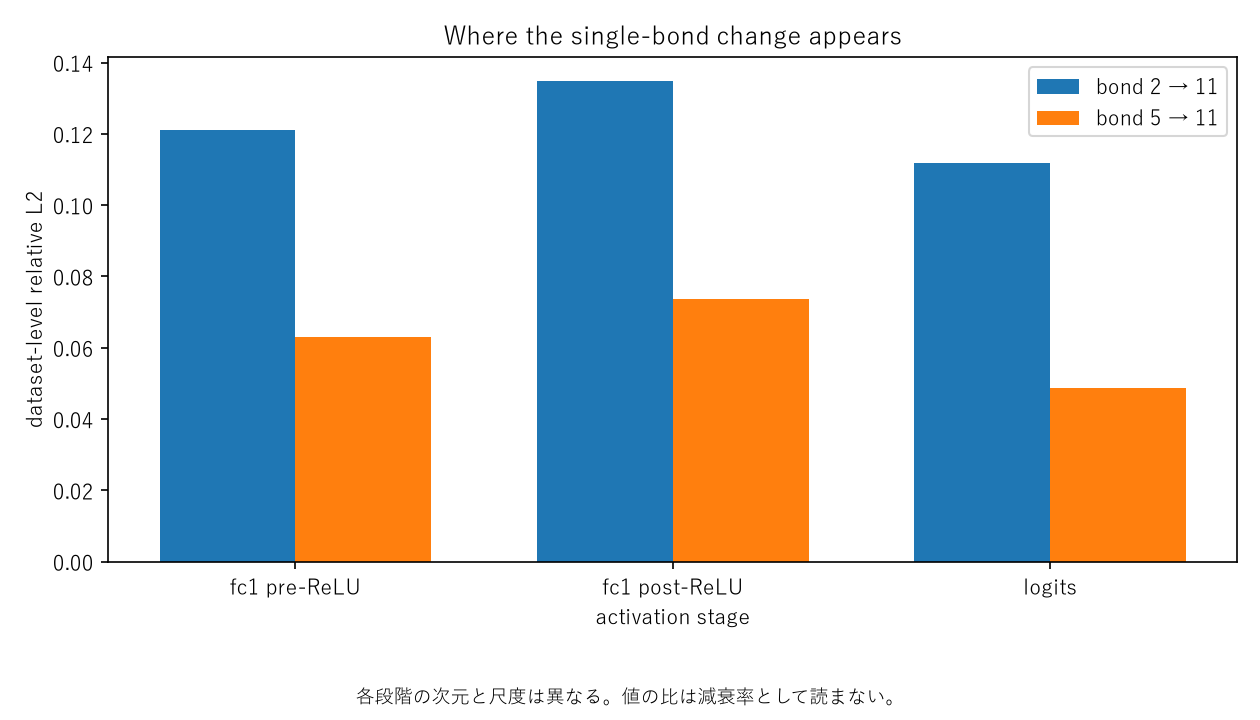

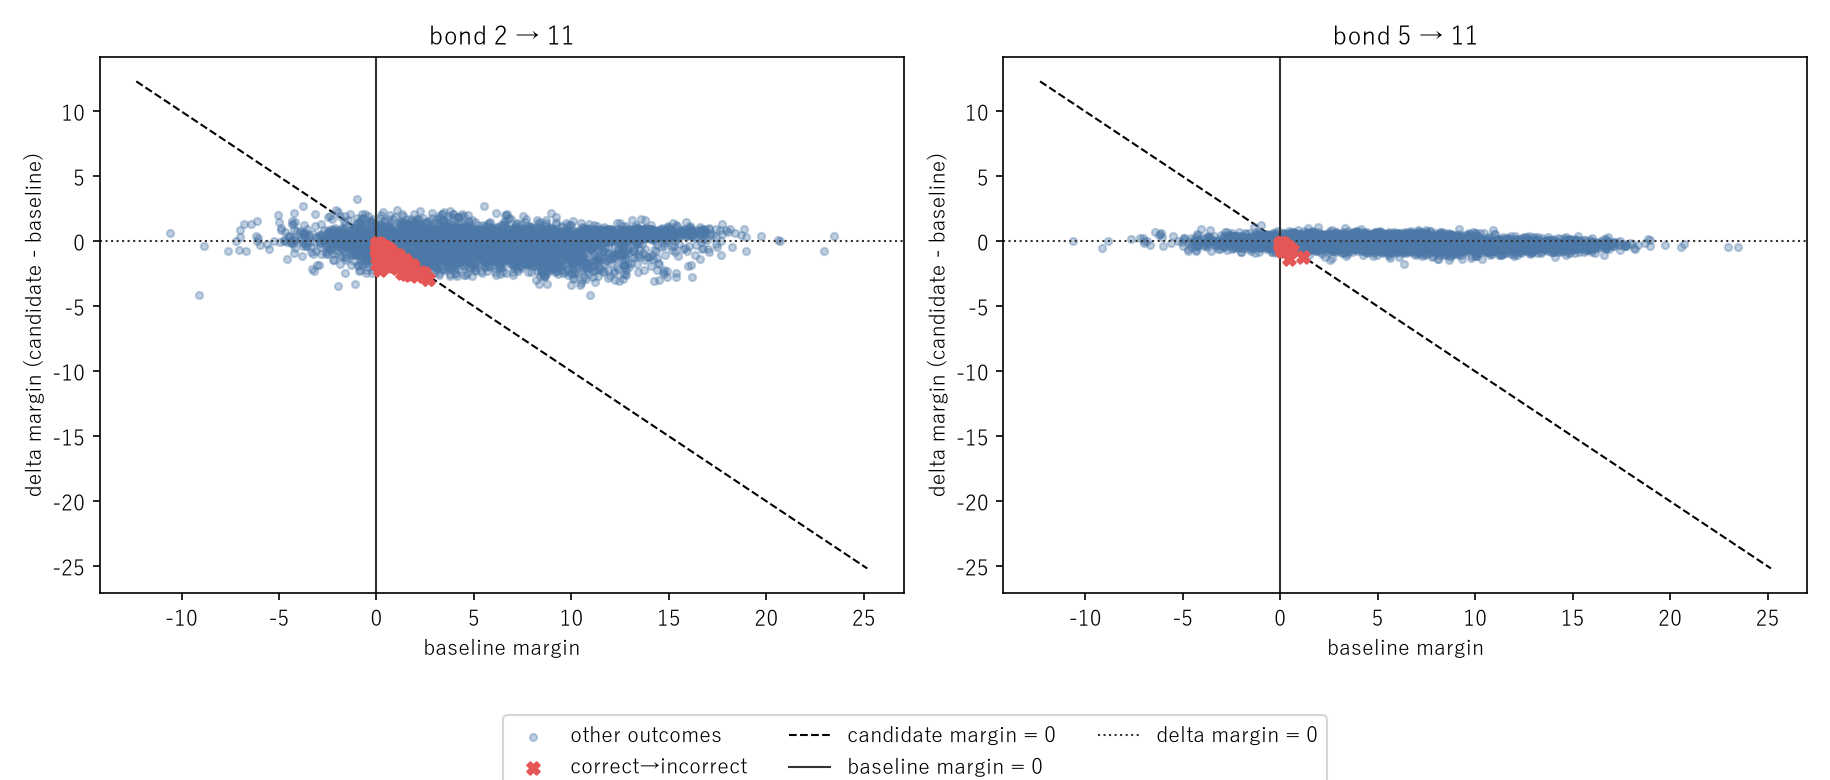

propagation diagnostic: D:\dev\nn-compression-svd-dmrg\results\40_dmrg\10_fashion_mnist_mlp\09_posthoc_single_bond_truncation_diagnostic\propagation_diagnostic


In [18]:
from fractions import Fraction

from torch.utils.data import SequentialSampler

PROPAGATION_BONDS = (2, 5)
PROPAGATION_TARGET_RANK = 11
PROPAGATION_SAMPLE_COUNT = 5_000
PROPAGATION_DIR = RESULTS_DIR / "propagation_diagnostic"
PARENT_RESULT_NAMES = (
    "candidate_results.csv",
    "baseline_metrics.json",
    "control_verification.json",
    "bond_singular_values.csv",
    "config.json",
    "environment.json",
)
PROPAGATION_STAGE_NAMES = ("fc1_pre_relu", "fc1_post_relu", "logits")
PROPAGATION_SUMMARY_FIELDS = (
    "diagnostic_id",
    "parent_run_id",
    "bond_index",
    "target_rank",
    "sample_count",
    "rank_selection_validation_loss",
    "rank_selection_validation_accuracy",
    "saved_loss",
    "saved_accuracy",
    "delta_loss",
    "delta_accuracy",
    "baseline_loss",
    "baseline_accuracy",
    "fc1_pre_relu_dataset_relative_l2",
    "fc1_pre_relu_diff_l2_mean",
    "fc1_pre_relu_diff_l2_median",
    "fc1_pre_relu_diff_l2_p90",
    "fc1_pre_relu_diff_l2_p95",
    "fc1_pre_relu_diff_l2_max",
    "fc1_post_relu_dataset_relative_l2",
    "fc1_post_relu_diff_l2_mean",
    "fc1_post_relu_diff_l2_median",
    "fc1_post_relu_diff_l2_p90",
    "fc1_post_relu_diff_l2_p95",
    "fc1_post_relu_diff_l2_max",
    "logits_dataset_relative_l2",
    "logits_diff_l2_mean",
    "logits_diff_l2_median",
    "logits_diff_l2_p90",
    "logits_diff_l2_p95",
    "logits_diff_l2_max",
    "delta_margin_mean",
    "delta_margin_median",
    "delta_margin_p10",
    "delta_margin_p90",
    "margin_worsened_count",
    "correct_to_correct",
    "correct_to_incorrect",
    "incorrect_to_correct",
    "incorrect_to_incorrect",
    "prediction_changed_count",
)
PROPAGATION_SAMPLE_FIELDS = (
    "diagnostic_id",
    "parent_run_id",
    "bond_index",
    "target_rank",
    "sample_order",
    "dataset_index",
    "label",
    "baseline_prediction",
    "candidate_prediction",
    "baseline_correct",
    "candidate_correct",
    "prediction_changed",
    "baseline_margin",
    "candidate_margin",
    "delta_margin",
    "fc1_pre_relu_diff_l2",
    "fc1_pre_relu_baseline_l2",
    "fc1_post_relu_diff_l2",
    "fc1_post_relu_baseline_l2",
    "logits_diff_l2",
    "logits_baseline_l2",
)


def propagation_diagnostic_id(parent_run_id, implementation_sha256):
    """診断条件だけの ID。時刻と絶対パスは入れない。"""
    payload = {
        "parent_run_id": parent_run_id,
        "notebook_code_sha256": implementation_sha256,
        "bonds": list(PROPAGATION_BONDS),
        "target_rank": PROPAGATION_TARGET_RANK,
        "evaluation_split": "rank_selection_validation",
        "evaluation_samples": PROPAGATION_SAMPLE_COUNT,
        "validation_batch_size": VALIDATION_BATCH_SIZE,
        "shuffle": False,
        "drop_last": False,
        "device": "cpu",
        "dtype": "float32",
        "stages": list(PROPAGATION_STAGE_NAMES),
        "margin": "correct_class_logit_minus_max_other_logit",
        "loss_recheck_atol": LOSS_RECHECK_ATOL,
    }
    canonical = json.dumps(payload, ensure_ascii=False, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()


def _require_config_value(config, key, expected):
    if key not in config or config[key] != expected:
        raise RuntimeError(
            "既存 config の設定が現在の Notebook と違うため、以前の結果に対応する追加診断は実行しません: "
            f"{key} saved={config.get(key)!r} current={expected!r}"
        )


def load_consistent_parent_run(results_dir):
    """既存09成果物の run_id と実験設定が、保存済み実装ハッシュから再計算できることを確認する。"""
    results_dir = Path(results_dir)
    missing = [name for name in PARENT_RESULT_NAMES if not (results_dir / name).is_file()]
    if missing:
        raise RuntimeError(
            "既存09の成果物が無いため、追加診断を以前の結果へ対応づけられません: " + ", ".join(missing)
        )
    identifiers = {name: stored_run_id(results_dir / name) for name in PARENT_RESULT_NAMES}
    if len(set(identifiers.values())) != 1:
        detail = ", ".join(f"{name}={value}" for name, value in identifiers.items())
        raise RuntimeError("既存09成果物の run_id が一致しません。上書きも削除もせず停止します: " + detail)
    config = json.loads((results_dir / "config.json").read_text(encoding="utf-8"))
    parent_run_id = identifiers["config.json"]
    for key in ("run_id", "notebook_code_sha256", "checkpoint_sha256", "split_index_sha256"):
        if not isinstance(config.get(key), str) or config[key] == "":
            raise RuntimeError(
                f"config.json に {key} がありません。移行も上書きもせず、追加診断は開始しません。"
            )
    if config["run_id"] != parent_run_id:
        raise RuntimeError("config.json の run_id が他の既存成果物と一致しません。")
    recomputed = run_identity(
        config["checkpoint_sha256"],
        config["split_index_sha256"],
        config["notebook_code_sha256"],
    )
    if recomputed != parent_run_id:
        raise RuntimeError(
            "保存済み run_id が checkpoint、データ分割、保存済み実装ハッシュ、実験設定から再計算した値と一致しません。"
            "以前の結果に対応する追加診断としては実行しません。"
        )
    _require_config_value(config, "out_modes", list(OUT_MODES))
    _require_config_value(config, "in_modes", list(IN_MODES))
    _require_config_value(config, "expected_ranks", list(EXPECTED_RANKS))
    _require_config_value(config, "bond_indices", list(BOND_INDICES))
    _require_config_value(config, "target_ranks", list(TARGET_RANKS))
    _require_config_value(config, "split_direction", SPLIT_DIRECTION)
    _require_config_value(config, "evaluation_split", "rank_selection_validation")
    _require_config_value(config, "validation_batch_size", VALIDATION_BATCH_SIZE)
    _require_config_value(config, "device", "cpu")
    _require_config_value(config, "loss_recheck_atol", LOSS_RECHECK_ATOL)
    _require_config_value(config, "canonicality_tolerance", CANONICALITY_TOLERANCE)
    _require_config_value(config, "float32_reconstruction_tolerance", FLOAT32_RECONSTRUCTION_TOLERANCE)
    _require_config_value(config, "evaluation_samples", PROPAGATION_SAMPLE_COUNT)
    saved_control = json.loads((results_dir / "control_verification.json").read_text(encoding="utf-8"))
    if saved_control.get("passed") is not True or saved_control.get("run_id") != parent_run_id:
        raise RuntimeError("既存 control が通過していないか run_id が違うため、追加診断は開始しません。")
    controls = saved_control.get("controls")
    if not isinstance(controls, list):
        raise RuntimeError("既存 control_verification.json に controls がありません。")
    found = set()
    for row in controls:
        found.add((int(row["bond_index"]), int(row["target_rank"])))
    if (2, 12) not in found or (5, 12) not in found:
        raise RuntimeError("既存 control に bond 2 または bond 5 の 12→12 がありません。")
    frame = pd.read_csv(results_dir / "candidate_results.csv", dtype={"run_id": str})
    return config, parent_run_id, frame


def select_saved_metric(frame, parent_run_id, role, bond_index, target_rank):
    """既存 candidate_results.csv の対応 1 行を、評価前に特定する。"""
    for column in ("run_id", "role", "bond_index", "target_rank", "rank_selection_validation_loss", "rank_selection_validation_accuracy"):
        if column not in frame.columns:
            raise RuntimeError(f"candidate_results.csv に {column} 列がありません。追加診断は開始しません。")
    selected = frame[frame["run_id"].astype(str) == str(parent_run_id)]
    selected = selected[selected["role"].astype(str) == str(role)]
    selected = selected[pd.to_numeric(selected["target_rank"], errors="coerce") == int(target_rank)]
    if bond_index is None:
        bond_text = selected["bond_index"].astype(str)
        selected = selected[selected["bond_index"].isna() | bond_text.isin(["", "nan"])]
    else:
        selected = selected[pd.to_numeric(selected["bond_index"], errors="coerce") == int(bond_index)]
    if len(selected) != 1:
        raise RuntimeError(
            "既存 candidate_results.csv に対応する行が 1 件ではありません: "
            f"role={role} bond={bond_index} target_rank={target_rank} count={len(selected)}。"
            "追加診断は保存せず停止します。"
        )
    row = selected.iloc[0]
    saved_loss = float(row["rank_selection_validation_loss"])
    saved_accuracy = float(row["rank_selection_validation_accuracy"])
    if not math.isfinite(saved_loss) or not math.isfinite(saved_accuracy):
        raise RuntimeError(
            "既存 candidate_results.csv の loss または accuracy が有限ではありません: "
            f"role={role} bond={bond_index} target_rank={target_rank}"
        )
    return saved_loss, saved_accuracy


def assert_recomputed_metrics_match(loss, accuracy, saved_loss, saved_accuracy, *, bond_index, target_rank, baseline_loss, baseline_accuracy):
    """既存の loss 許容と accuracy の一致条件で、保存済みの対応行と照合する。"""
    require_evaluation_metrics(
        loss,
        accuracy,
        baseline_loss,
        baseline_accuracy,
        bond_index=bond_index,
        target_rank=target_rank,
    )
    if abs(loss - saved_loss) > LOSS_RECHECK_ATOL or accuracy != saved_accuracy:
        raise RuntimeError(
            "追加診断の loss・accuracy が既存 candidate_results.csv と一致しません: "
            f"bond={bond_index} target_rank={target_rank} "
            f"loss={loss!r} saved_loss={saved_loss!r} accuracy={accuracy!r} saved_accuracy={saved_accuracy!r}。"
            "結果は保存しません。"
        )


def _diagnostic_identifiers(path):
    path = Path(path)
    if path.suffix == ".json":
        payload = json.loads(path.read_text(encoding="utf-8"))
        diagnostic_id = payload.get("diagnostic_id")
        parent_run_id = payload.get("parent_run_id")
        if not isinstance(diagnostic_id, str) or diagnostic_id == "" or not isinstance(parent_run_id, str) or parent_run_id == "":
            raise RuntimeError(
                f"{path.name} に diagnostic_id または parent_run_id がありません。"
                "移行も上書きも削除もせず停止します。"
            )
        return diagnostic_id, parent_run_id
    frame = pd.read_csv(path, dtype={"diagnostic_id": str, "parent_run_id": str})
    if frame.empty or "diagnostic_id" not in frame.columns or "parent_run_id" not in frame.columns:
        raise RuntimeError(
            f"{path.name} に診断 ID がありません。移行も上書きも削除もせず停止します。"
        )
    diagnostic_ids = {str(value) for value in frame["diagnostic_id"]}
    parent_ids = {str(value) for value in frame["parent_run_id"]}
    if len(diagnostic_ids) != 1 or len(parent_ids) != 1:
        raise RuntimeError(f"{path.name} の診断 ID が 1 組ではありません。上書きも削除もせず停止します。")
    return diagnostic_ids.pop(), parent_ids.pop()


def assert_saved_diagnostic_matches(directory, diagnostic_id, parent_run_id):
    """評価前に呼ぶ。不一致の保存済み診断は、上書きも削除もしない。"""
    directory = Path(directory)
    if not directory.exists():
        return
    files = [path for path in directory.iterdir() if path.is_file()]
    if not files:
        return
    identity_names = {
        "diagnostic_config.json",
        "diagnostic_summary.csv",
        "diagnostic_per_sample.csv",
    }
    config_path = directory / "diagnostic_config.json"
    if not config_path.is_file():
        names = ", ".join(sorted(path.name for path in files))
        raise RuntimeError(
            "追加診断ディレクトリに識別情報のないファイルがあります。"
            f"移行も上書きも削除もせず停止します: {names}"
        )
    found_id, found_parent = _diagnostic_identifiers(config_path)
    if found_id != diagnostic_id or found_parent != parent_run_id:
        raise RuntimeError(
            "保存済み追加診断の ID が今回と違うため、上書きも削除もせず停止します: "
            f"saved_diagnostic_id={found_id} current_diagnostic_id={diagnostic_id} "
            f"saved_parent_run_id={found_parent} current_parent_run_id={parent_run_id}"
        )
    for path in files:
        if path.suffix == ".png":
            continue
        if path.name not in identity_names:
            raise RuntimeError(f"追加診断ディレクトリに未定義のファイルがあります。削除せず停止します: {path.name}")
        if path == config_path:
            continue
        file_id, file_parent = _diagnostic_identifiers(path)
        if file_id != diagnostic_id or file_parent != parent_run_id:
            raise RuntimeError(
                f"{path.name} の診断 ID が config と違うため、上書きも削除もせず停止します。"
            )


def capture_internal_outputs(model, images):
    """MNISTMLP.forward の fc1 出力、ReLU 後、戻り値 logits を hook で取る。"""
    if model.relu1.inplace:
        raise RuntimeError("inplace ReLU では fc1 の ReLU 前出力を別に保持できません。")
    captured = {}

    def save_pre(module, inputs, output):
        captured["pre"] = output

    def save_post(module, inputs, output):
        captured["post"] = output

    pre_handle = model.fc1.register_forward_hook(save_pre)
    post_handle = model.relu1.register_forward_hook(save_post)
    try:
        model.eval()
        with torch.inference_mode():
            logits = model(images)
    finally:
        pre_handle.remove()
        post_handle.remove()
    if "pre" not in captured or "post" not in captured:
        raise RuntimeError("fc1 または ReLU1 の出力を取得できませんでした。")
    pre = captured["pre"].detach().cpu().clone()
    post = captured["post"].detach().cpu().clone()
    logits = logits.detach().cpu().clone()
    if pre.dtype != torch.float32 or post.dtype != torch.float32 or logits.dtype != torch.float32:
        raise RuntimeError("内部出力が float32 ではありません。")
    if not torch.isfinite(pre).all() or not torch.isfinite(post).all() or not torch.isfinite(logits).all():
        raise RuntimeError("内部出力に非有限値があります。0 へは置き換えません。")
    return pre, post, logits


def assert_capture_preserves_model(model, images):
    """通常 forward と hook の logits が一致し、取得後も forward と parameter が変わらないことを確認する。"""
    before = clone_state(model)
    model.eval()
    with torch.inference_mode():
        direct = model(images).detach().cpu().clone()
    pre, post, hooked = capture_internal_outputs(model, images)
    if not torch.equal(hooked, direct):
        raise RuntimeError("hook で取得した logits が通常 forward と一致しません。")
    with torch.inference_mode():
        again = model(images).detach().cpu().clone()
    if not torch.equal(again, direct):
        raise RuntimeError("内部出力の取得後に forward の結果が変わりました。")
    if not states_equal(clone_state(model), before):
        raise RuntimeError("内部出力の取得で parameter が変わりました。")
    if pre.shape[0] != images.shape[0] or post.shape != pre.shape or hooked.shape[0] != images.shape[0]:
        raise RuntimeError("内部出力の batch サイズが入力と一致しません。")
    return pre, post, hooked


def _finite_statistic(values, quantile):
    if values.ndim != 1 or values.numel() < 1:
        raise RuntimeError("分布集計の対象が空です。")
    if not torch.isfinite(values).all():
        raise RuntimeError("分布集計の対象に非有限値があります。0 へは置き換えません。")
    result = torch.quantile(values, float(quantile))
    if not torch.isfinite(result):
        raise RuntimeError("分位点が有限ではありません。")
    return float(result)


def stage_change_summary(candidate, baseline, stage_name):
    """サンプルごとの L2 と、データ全体の relative L2 を返す。分母が 0 なら停止する。"""
    if candidate.shape != baseline.shape or candidate.ndim != 2:
        raise RuntimeError(f"{stage_name} の出力形状が baseline と一致しません: {tuple(candidate.shape)} vs {tuple(baseline.shape)}")
    if candidate.shape[0] < 1:
        raise RuntimeError(f"{stage_name} の対象サンプルが空です。")
    difference = candidate.to(dtype=torch.float64) - baseline.to(dtype=torch.float64)
    baseline64 = baseline.to(dtype=torch.float64)
    if not torch.isfinite(difference).all() or not torch.isfinite(baseline64).all():
        raise RuntimeError(f"{stage_name} に非有限値があります。相対 L2 は計算せず、0 へも置き換えません。")
    diff_l2 = torch.linalg.vector_norm(difference, dim=1)
    baseline_l2 = torch.linalg.vector_norm(baseline64, dim=1)
    denominator = torch.linalg.vector_norm(baseline64)
    if not torch.isfinite(denominator) or float(denominator) == 0.0:
        raise RuntimeError(
            f"{stage_name} の dataset-level relative L2 の分母がゼロです。epsilon には置き換えず停止します。"
        )
    numerator = torch.linalg.vector_norm(difference)
    if not torch.isfinite(numerator) or not torch.isfinite(diff_l2).all() or not torch.isfinite(baseline_l2).all():
        raise RuntimeError(f"{stage_name} の L2 norm が有限ではありません。")
    relative = numerator / denominator
    if not torch.isfinite(relative):
        raise RuntimeError(f"{stage_name} の dataset-level relative L2 が有限ではありません。")
    mean = diff_l2.mean()
    if not torch.isfinite(mean):
        raise RuntimeError(f"{stage_name} の差分 L2 の平均が有限ではありません。")
    return {
        "dataset_relative_l2": float(relative),
        "diff_l2": diff_l2,
        "baseline_l2": baseline_l2,
        "diff_l2_mean": float(mean),
        "diff_l2_median": _finite_statistic(diff_l2, 0.5),
        "diff_l2_p90": _finite_statistic(diff_l2, 0.9),
        "diff_l2_p95": _finite_statistic(diff_l2, 0.95),
        "diff_l2_max": float(diff_l2.max()),
    }


def class_margins(logits, labels):
    """margin = 正解クラスの logit - 正解クラス以外の最大 logit。"""
    if logits.ndim != 2 or labels.ndim != 1 or logits.shape[0] != labels.shape[0]:
        raise RuntimeError("margin の logits と labels の形が合いません。")
    if not torch.isfinite(logits).all():
        raise RuntimeError("logits に非有限値があるため、margin は計算しません。")
    labels = labels.to(dtype=torch.int64)
    class_count = int(logits.shape[1])
    if class_count < 2 or int(labels.min()) < 0 or int(labels.max()) >= class_count:
        raise RuntimeError("正解ラベルがクラス番号の範囲外です。")
    correct = logits.gather(1, labels.view(-1, 1)).squeeze(1)
    masked = logits.clone()
    masked.scatter_(1, labels.view(-1, 1), float("-inf"))
    other = masked.max(dim=1).values
    if not torch.isfinite(other).all():
        raise RuntimeError("正解以外の最大 logit が有限ではありません。")
    margin = correct - other
    if not torch.isfinite(margin).all():
        raise RuntimeError("margin が有限ではありません。")
    return margin


def margin_change_summary(baseline_margin, candidate_margin):
    if baseline_margin.shape != candidate_margin.shape or baseline_margin.ndim != 1:
        raise RuntimeError("baseline と candidate の margin の形が一致しません。")
    if not torch.isfinite(baseline_margin).all() or not torch.isfinite(candidate_margin).all():
        raise RuntimeError("margin に非有限値があります。0 へは置き換えません。")
    delta = candidate_margin.to(dtype=torch.float64) - baseline_margin.to(dtype=torch.float64)
    if not torch.isfinite(delta).all():
        raise RuntimeError("delta_margin が有限ではありません。")
    mean = delta.mean()
    if not torch.isfinite(mean):
        raise RuntimeError("delta_margin の平均が有限ではありません。")
    return {
        "delta_margin": delta,
        "delta_margin_mean": float(mean),
        "delta_margin_median": _finite_statistic(delta, 0.5),
        "delta_margin_p10": _finite_statistic(delta, 0.1),
        "delta_margin_p90": _finite_statistic(delta, 0.9),
        "margin_worsened_count": int((delta < 0).sum()),
    }


def prediction_transition_summary(labels, baseline_prediction, candidate_prediction, baseline_accuracy, candidate_accuracy):
    """正誤遷移と予測変更数を分け、accuracy 差を件数の有理数で検証する。

    float の ``candidate_accuracy - baseline_accuracy`` は、
    ``(incorrect→correct - correct→incorrect) / 5000`` とビット一致しないことがある。
    検証は正解件数から作った有理数で行う。
    """
    labels = labels.to(dtype=torch.int64).view(-1)
    baseline_prediction = baseline_prediction.to(dtype=torch.int64).view(-1)
    candidate_prediction = candidate_prediction.to(dtype=torch.int64).view(-1)
    count = int(labels.shape[0])
    if (
        count != PROPAGATION_SAMPLE_COUNT
        or baseline_prediction.shape[0] != count
        or candidate_prediction.shape[0] != count
    ):
        raise RuntimeError(f"正誤遷移のサンプル数が 5,000 ではありません: {count}")
    baseline_hit = baseline_prediction.eq(labels)
    candidate_hit = candidate_prediction.eq(labels)
    correct_to_correct = int((baseline_hit & candidate_hit).sum())
    correct_to_incorrect = int((baseline_hit & ~candidate_hit).sum())
    incorrect_to_correct = int((~baseline_hit & candidate_hit).sum())
    incorrect_to_incorrect = int((~baseline_hit & ~candidate_hit).sum())
    if correct_to_correct + correct_to_incorrect + incorrect_to_correct + incorrect_to_incorrect != count:
        raise RuntimeError("正誤遷移の合計がサンプル数と一致しません。")
    prediction_changed = baseline_prediction.ne(candidate_prediction)
    prediction_changed_count = int(prediction_changed.sum())
    if int((baseline_hit & candidate_hit & prediction_changed).sum()) != 0:
        raise RuntimeError("correct→correct で予測クラスが変化しています。")
    incorrect_changed_class = int((~baseline_hit & ~candidate_hit & prediction_changed).sum())
    if prediction_changed_count != correct_to_incorrect + incorrect_to_correct + incorrect_changed_class:
        raise RuntimeError(
            "予測変更数が正誤遷移の内訳と一致しません: "
            f"changed={prediction_changed_count} correct_to_incorrect={correct_to_incorrect} "
            f"incorrect_to_correct={incorrect_to_correct} incorrect_class_changed={incorrect_changed_class}"
        )
    baseline_correct_count = correct_to_correct + correct_to_incorrect
    candidate_correct_count = correct_to_correct + incorrect_to_correct
    if baseline_accuracy != baseline_correct_count / count:
        raise RuntimeError(
            "baseline accuracy が正解件数 / 5000 と一致しません: "
            f"accuracy={baseline_accuracy!r} count={baseline_correct_count}"
        )
    if candidate_accuracy != candidate_correct_count / count:
        raise RuntimeError(
            "candidate accuracy が正解件数 / 5000 と一致しません: "
            f"accuracy={candidate_accuracy!r} count={candidate_correct_count}"
        )
    difference = incorrect_to_correct - correct_to_incorrect
    if Fraction(candidate_correct_count, count) - Fraction(baseline_correct_count, count) != Fraction(difference, count):
        raise RuntimeError("accuracy 差が (incorrect→correct - correct→incorrect) / 5000 と一致しません。")
    return {
        "correct_to_correct": correct_to_correct,
        "correct_to_incorrect": correct_to_incorrect,
        "incorrect_to_correct": incorrect_to_correct,
        "incorrect_to_incorrect": incorrect_to_incorrect,
        "prediction_changed_count": prediction_changed_count,
        "accuracy_delta_from_counts": difference / count,
    }


def rank_selection_dataset_indices(dataset):
    raw = getattr(dataset, "indices", None)
    if raw is None:
        raise RuntimeError("rank-selection validation を元の Fashion-MNIST training index で識別できません。")
    indices = [int(value) for value in list(raw)]
    if len(indices) != len(dataset):
        raise RuntimeError("dataset index の長さがサンプル数と違います。")
    if len(indices) != PROPAGATION_SAMPLE_COUNT or len(set(indices)) != len(indices):
        raise RuntimeError("rank-selection validation の index が 5,000 件の一意な列ではありません。")
    return indices


def rank_selection_loader(dataset):
    loader = make_loader(dataset)
    if not isinstance(loader.sampler, SequentialSampler) or loader.drop_last:
        raise RuntimeError("診断の DataLoader は shuffle=False かつ drop_last=False である必要があります。")
    if int(loader.batch_size) != VALIDATION_BATCH_SIZE:
        raise RuntimeError("診断の batch size が rank-selection validation の設定と違います。")
    return loader


def _require_cpu_float32(model):
    if not isinstance(model, MNISTMLP):
        raise RuntimeError("診断対象が MNISTMLP ではありません。")
    if not isinstance(model.relu1, nn.ReLU) or model.relu1.inplace:
        raise RuntimeError("fc1 の直後が非 inplace の ReLU ではありません。")
    if not isinstance(model.fc2, nn.Linear) or not isinstance(model.relu2, nn.ReLU) or not isinstance(model.fc3, nn.Linear):
        raise RuntimeError("fc1 より後段の層構成が MNISTMLP と違います。")
    for name, parameter in model.named_parameters():
        if parameter.dtype != torch.float32 or parameter.device.type != "cpu":
            raise RuntimeError(f"診断 parameter が CPU の float32 ではありません: {name}")
    model.eval()


def collect_model_outputs(model, dataset):
    """shuffle しない rank-selection validation から、fc1 と logits を 1 回の forward で集める。"""
    _require_cpu_float32(model)
    indices = rank_selection_dataset_indices(dataset)
    loader = rank_selection_loader(dataset)
    pre_parts = []
    post_parts = []
    logit_parts = []
    label_parts = []
    position = 0
    for images, labels in loader:
        if images.device.type != "cpu" or images.dtype != torch.float32:
            raise RuntimeError("診断入力が CPU の float32 ではありません。")
        pre, post, logits = capture_internal_outputs(model, images)
        batch = int(images.shape[0])
        if pre.shape[0] != batch or post.shape[0] != batch or logits.shape[0] != batch or int(labels.shape[0]) != batch:
            raise RuntimeError("内部出力の件数が batch と一致しません。")
        pre_parts.append(pre)
        post_parts.append(post)
        logit_parts.append(logits)
        label_parts.append(labels.detach().cpu().to(dtype=torch.int64).clone())
        position += batch
    if position != len(indices):
        raise RuntimeError("DataLoader が rank-selection validation の全件を返していません。")
    return {
        "dataset_index": indices,
        "fc1_pre_relu": torch.cat(pre_parts, dim=0),
        "fc1_post_relu": torch.cat(post_parts, dim=0),
        "logits": torch.cat(logit_parts, dim=0),
        "label": torch.cat(label_parts, dim=0),
    }


def assert_bond_round_trip_control(
    model,
    bond_index,
    original_state,
    reference_weight,
    baseline_logits,
    images,
    rank_dataset,
    baseline_loss,
    baseline_accuracy,
):
    """対象 bond だけの 12→12 control。既存の許容と照合関数を使う。"""
    candidate, split, canonicality = build_single_bond(model, bond_index, 12)
    assert_outside_parameters_unchanged(candidate, original_state)
    if actual_ranks_of(candidate) != EXPECTED_RANKS:
        raise RuntimeError(f"12→12 control の rank 列が元モデルと違います: bond={bond_index}")
    discarded = discarded_from_split(split)
    relative_error = relative_weight_error(reference_weight, candidate)
    assert_discarded_matches_weight(relative_error, discarded["sqrt_relative_discarded_weight"])
    relative_logits = assert_control_weight_and_logits(candidate, reference_weight, baseline_logits, images)
    candidate.eval()
    loss, accuracy = evaluate_rank_selection(candidate, rank_dataset)
    require_evaluation_metrics(
        loss,
        accuracy,
        baseline_loss,
        baseline_accuracy,
        bond_index=bond_index,
        target_rank=12,
    )
    if abs(loss - baseline_loss) > LOSS_RECHECK_ATOL or accuracy != baseline_accuracy:
        raise RuntimeError(
            "12→12 control の rank-selection 指標が基準と一致しません: "
            f"bond={bond_index} loss={loss} accuracy={accuracy}"
        )
    del candidate
    return {
        "bond_index": int(bond_index),
        "target_rank": 12,
        "passed": True,
        "canonicality_max_error": canonicality,
        "fixed_input_logits_relative_l2": relative_logits,
    }


def plot_stage_relative_l2(summary_rows):
    """段階ごとの dataset-level relative L2。段階間の比は描かない。"""
    if [int(row["bond_index"]) for row in summary_rows] != [2, 5]:
        raise RuntimeError("relative L2 の図は bond 2 と bond 5 の 2 行が必要です。")
    stage_labels = ("fc1 pre-ReLU", "fc1 post-ReLU", "logits")
    figure, axis = plt.subplots(figsize=(8.4, 4.8))
    centers = [float(index) for index in range(len(stage_labels))]
    width = 0.36
    for offset, row in ((-width / 2, summary_rows[0]), (width / 2, summary_rows[1])):
        values = [float(row[f"{stage}_dataset_relative_l2"]) for stage in PROPAGATION_STAGE_NAMES]
        if not all(math.isfinite(value) for value in values):
            raise RuntimeError("relative L2 の図に非有限値があります。")
        axis.bar([center + offset for center in centers], values, width=width, label=f"bond {int(row['bond_index'])} → 11")
    axis.set_xticks(centers)
    axis.set_xticklabels(stage_labels)
    axis.set_ylabel("dataset-level relative L2")
    axis.set_xlabel("activation stage")
    axis.set_title("Where the single-bond change appears")
    axis.legend()
    figure.tight_layout()
    figure.subplots_adjust(bottom=0.22)
    figure.text(
        0.5,
        0.02,
        "各段階の次元と尺度は異なる。値の比は減衰率として読まない。",
        ha="center",
        va="bottom",
        fontsize=9,
    )
    return figure


def plot_margin_scatter(sample_rows):
    """baseline margin と delta margin。correct→incorrect だけ記号を変える。"""
    figure, axes = plt.subplots(1, 2, figsize=(12.2, 5.2), sharex=False, sharey=False)
    for axis, bond_index in zip(axes, PROPAGATION_BONDS):
        rows = [row for row in sample_rows if int(row["bond_index"]) == int(bond_index)]
        if not rows:
            raise RuntimeError(f"bond {bond_index} の margin 図に行がありません。")
        orders = [int(row["sample_order"]) for row in rows]
        if len(orders) != len(set(orders)):
            raise RuntimeError(f"bond {bond_index} の margin 図で sample_order が重複しています。")
        other_x = []
        other_y = []
        flip_x = []
        flip_y = []
        for row in rows:
            x_value = float(row["baseline_margin"])
            y_value = float(row["delta_margin"])
            if not math.isfinite(x_value) or not math.isfinite(y_value):
                raise RuntimeError("margin 図に非有限値があります。")
            flipped = int(row["baseline_correct"]) == 1 and int(row["candidate_correct"]) == 0
            if flipped:
                flip_x.append(x_value)
                flip_y.append(y_value)
            else:
                other_x.append(x_value)
                other_y.append(y_value)
        axis.scatter(other_x, other_y, s=12, alpha=0.35, c="#4c78a8", label="other outcomes", zorder=2)
        axis.scatter(flip_x, flip_y, s=36, marker="X", c="#e45756", label="correct→incorrect", zorder=3)
        x_values = other_x + flip_x
        low = min(x_values)
        high = max(x_values)
        pad = 0.05 * (high - low) if high > low else 1.0
        guide = [low - pad, high + pad]
        axis.plot(guide, [-value for value in guide], color="black", linestyle="--", linewidth=1.0, label="candidate margin = 0", zorder=1)
        axis.axvline(0.0, color="#333333", linewidth=1.0, label="baseline margin = 0")
        axis.axhline(0.0, color="#333333", linewidth=1.0, linestyle=":", label="delta margin = 0")
        axis.set_title(f"bond {int(bond_index)} → 11")
        axis.set_xlabel("baseline margin")
        axis.set_ylabel("delta margin (candidate - baseline)")
    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
    figure.tight_layout()
    figure.subplots_adjust(bottom=0.24)
    return figure


def _python_float(value):
    result = float(value)
    if not math.isfinite(result):
        raise RuntimeError(f"保存前の値が有限ではありません: {result!r}")
    return result


def build_propagation_rows(diagnostic_id, parent_run_id, bond_index, saved_loss, saved_accuracy, evaluated, baseline_outputs, candidate_outputs):
    if baseline_outputs["label"].shape[0] != PROPAGATION_SAMPLE_COUNT:
        raise RuntimeError("baseline の診断サンプル数が 5,000 ではありません。")
    if not torch.equal(baseline_outputs["label"], candidate_outputs["label"]):
        raise RuntimeError("baseline と candidate でラベル順が一致しません。")
    if baseline_outputs["dataset_index"] != candidate_outputs["dataset_index"]:
        raise RuntimeError("baseline と candidate で dataset index が一致しません。")
    labels = baseline_outputs["label"]
    baseline_prediction = torch.argmax(baseline_outputs["logits"], dim=1)
    candidate_prediction = torch.argmax(candidate_outputs["logits"], dim=1)
    baseline_accuracy_from_logits = float(baseline_prediction.eq(labels).sum().item() / PROPAGATION_SAMPLE_COUNT)
    candidate_accuracy_from_logits = float(candidate_prediction.eq(labels).sum().item() / PROPAGATION_SAMPLE_COUNT)
    if baseline_accuracy_from_logits != evaluated["baseline_accuracy"] or candidate_accuracy_from_logits != evaluated["accuracy"]:
        raise RuntimeError(
            "内部 logits から計算した accuracy が evaluate の accuracy と一致しません: "
            f"bond={bond_index}"
        )
    stages = {}
    for stage_name in PROPAGATION_STAGE_NAMES:
        stages[stage_name] = stage_change_summary(
            candidate_outputs[stage_name],
            baseline_outputs[stage_name],
            stage_name,
        )
    baseline_margin = class_margins(baseline_outputs["logits"], labels)
    candidate_margin = class_margins(candidate_outputs["logits"], labels)
    margin_summary = margin_change_summary(baseline_margin, candidate_margin)
    transitions = prediction_transition_summary(
        labels,
        baseline_prediction,
        candidate_prediction,
        evaluated["baseline_accuracy"],
        evaluated["accuracy"],
    )
    summary = {
        "diagnostic_id": diagnostic_id,
        "parent_run_id": parent_run_id,
        "bond_index": int(bond_index),
        "target_rank": PROPAGATION_TARGET_RANK,
        "sample_count": PROPAGATION_SAMPLE_COUNT,
        "rank_selection_validation_loss": _python_float(evaluated["loss"]),
        "rank_selection_validation_accuracy": _python_float(evaluated["accuracy"]),
        "saved_loss": _python_float(saved_loss),
        "saved_accuracy": _python_float(saved_accuracy),
        "delta_loss": _python_float(evaluated["delta_loss"]),
        "delta_accuracy": _python_float(evaluated["delta_accuracy"]),
        "baseline_loss": _python_float(evaluated["baseline_loss"]),
        "baseline_accuracy": _python_float(evaluated["baseline_accuracy"]),
        "delta_margin_mean": margin_summary["delta_margin_mean"],
        "delta_margin_median": margin_summary["delta_margin_median"],
        "delta_margin_p10": margin_summary["delta_margin_p10"],
        "delta_margin_p90": margin_summary["delta_margin_p90"],
        "margin_worsened_count": margin_summary["margin_worsened_count"],
        "correct_to_correct": transitions["correct_to_correct"],
        "correct_to_incorrect": transitions["correct_to_incorrect"],
        "incorrect_to_correct": transitions["incorrect_to_correct"],
        "incorrect_to_incorrect": transitions["incorrect_to_incorrect"],
        "prediction_changed_count": transitions["prediction_changed_count"],
    }
    for stage_name in PROPAGATION_STAGE_NAMES:
        summary[f"{stage_name}_dataset_relative_l2"] = stages[stage_name]["dataset_relative_l2"]
        for stat_name in ("mean", "median", "p90", "p95", "max"):
            summary[f"{stage_name}_diff_l2_{stat_name}"] = stages[stage_name][f"diff_l2_{stat_name}"]
    sample_rows = []
    delta_margin = margin_summary["delta_margin"]
    for position, dataset_index in enumerate(baseline_outputs["dataset_index"]):
        sample_rows.append(
            {
                "diagnostic_id": diagnostic_id,
                "parent_run_id": parent_run_id,
                "bond_index": int(bond_index),
                "target_rank": PROPAGATION_TARGET_RANK,
                "sample_order": position,
                "dataset_index": int(dataset_index),
                "label": int(labels[position]),
                "baseline_prediction": int(baseline_prediction[position]),
                "candidate_prediction": int(candidate_prediction[position]),
                "baseline_correct": int(baseline_prediction[position] == labels[position]),
                "candidate_correct": int(candidate_prediction[position] == labels[position]),
                "prediction_changed": int(baseline_prediction[position] != candidate_prediction[position]),
                "baseline_margin": _python_float(baseline_margin[position]),
                "candidate_margin": _python_float(candidate_margin[position]),
                "delta_margin": _python_float(delta_margin[position]),
                "fc1_pre_relu_diff_l2": _python_float(stages["fc1_pre_relu"]["diff_l2"][position]),
                "fc1_pre_relu_baseline_l2": _python_float(stages["fc1_pre_relu"]["baseline_l2"][position]),
                "fc1_post_relu_diff_l2": _python_float(stages["fc1_post_relu"]["diff_l2"][position]),
                "fc1_post_relu_baseline_l2": _python_float(stages["fc1_post_relu"]["baseline_l2"][position]),
                "logits_diff_l2": _python_float(stages["logits"]["diff_l2"][position]),
                "logits_baseline_l2": _python_float(stages["logits"]["baseline_l2"][position]),
            }
        )
    return summary, sample_rows


def publish_propagation_diagnostic(directory, config, summary_rows, sample_rows):
    directory = Path(directory)
    if directory.parent != RESULTS_DIR or directory.name != "propagation_diagnostic":
        raise RuntimeError(f"追加診断の保存先が 09 の専用サブディレクトリではありません: {directory}")
    diagnostic_id = config["diagnostic_id"]
    parent_run_id = config["parent_run_id"]
    assert_saved_diagnostic_matches(directory, diagnostic_id, parent_run_id)
    paths = {
        "config": directory / "diagnostic_config.json",
        "summary": directory / "diagnostic_summary.csv",
        "samples": directory / "diagnostic_per_sample.csv",
        "stages": directory / "01_dataset_relative_l2_by_stage.png",
        "margins": directory / "02_baseline_margin_vs_delta_margin.png",
    }
    for path in paths.values():
        if path.parent != directory or path.name in PARENT_RESULT_NAMES:
            raise RuntimeError(f"既存09成果物、またはサブディレクトリ外への保存はしません: {path.name}")
    directory.mkdir(parents=True, exist_ok=True)
    assert_saved_diagnostic_matches(directory, diagnostic_id, parent_run_id)
    atomic_write_json(paths["config"], config)
    atomic_write_csv(paths["summary"], summary_rows, PROPAGATION_SUMMARY_FIELDS)
    atomic_write_csv(paths["samples"], sample_rows, PROPAGATION_SAMPLE_FIELDS)
    save_and_show(plot_stage_relative_l2(summary_rows), paths["stages"])
    save_and_show(plot_margin_scatter(sample_rows), paths["margins"])
    print("propagation diagnostic:", directory)


def run_propagation_diagnostic():
    if PROPAGATION_DIR.parent != RESULTS_DIR:
        raise RuntimeError("追加診断の保存先が 09 結果ディレクトリの直下ではありません。")
    config, parent_run_id, frame = load_consistent_parent_run(RESULTS_DIR)
    saved_metrics = {
        ("baseline", None, 12): select_saved_metric(frame, parent_run_id, "baseline", None, 12),
        ("truncation", 2, 11): select_saved_metric(frame, parent_run_id, "truncation", 2, 11),
        ("truncation", 5, 11): select_saved_metric(frame, parent_run_id, "truncation", 5, 11),
    }
    implementation_sha256 = current_implementation_sha256()
    diagnostic_id = propagation_diagnostic_id(parent_run_id, implementation_sha256)
    assert_saved_diagnostic_matches(PROPAGATION_DIR, diagnostic_id, parent_run_id)

    resolved, representative = resolve_notebook08_bests()
    checkpoint_sha = representative["best_sha256"]
    if checkpoint_sha != config["checkpoint_sha256"]:
        raise RuntimeError(
            "解決した checkpoint が既存 config の checkpoint_sha256 と一致しません。"
            "以前の結果に対応する追加診断としては実行しません。"
        )
    rank_dataset, split_sha = load_rank_selection_split()
    if split_sha != config["split_index_sha256"] or len(rank_dataset) != PROPAGATION_SAMPLE_COUNT:
        raise RuntimeError(
            "データ分割が既存 config の rank-selection validation と一致しません。"
            "以前の結果に対応する追加診断としては実行しません。"
        )
    model, payload = model_from_checkpoint(representative["best_path"])
    _require_cpu_float32(model)
    if not isinstance(model.fc1, TTLinear) or len(model.fc1.cores) != 6:
        raise RuntimeError("対象層が 6-core TTLinear ではありません。")
    if tuple(model.fc1.out_modes) != OUT_MODES or tuple(model.fc1.in_modes) != IN_MODES:
        raise RuntimeError("復元モデルの mode が契約と違います。")
    if list(payload["out_modes"]) != list(OUT_MODES) or list(payload["in_modes"]) != list(IN_MODES):
        raise RuntimeError("checkpoint の tensorization が契約と違います。")
    ranks = actual_ranks_of(model)
    assert_bond_index_contract(ranks)
    if ranks != EXPECTED_RANKS or list(payload["actual_ranks"]) != list(EXPECTED_RANKS):
        raise RuntimeError(f"actual ranks が {EXPECTED_RANKS} ではありません: {ranks}")
    original_state = clone_state(model)
    reference_weight = dense_fc1_weight(model)
    images = fixed_logits_input()
    assert_capture_preserves_model(model, images)
    with torch.inference_mode():
        baseline_logits = model(images).detach().cpu().clone()
    baseline_loss, baseline_accuracy = evaluate_rank_selection(model, rank_dataset)
    require_evaluation_metrics(
        baseline_loss,
        baseline_accuracy,
        baseline_loss,
        baseline_accuracy,
        bond_index="baseline",
        target_rank=12,
    )
    controls = []
    for bond_index in PROPAGATION_BONDS:
        controls.append(
            assert_bond_round_trip_control(
                model,
                bond_index,
                original_state,
                reference_weight,
                baseline_logits,
                images,
                rank_dataset,
                baseline_loss,
                baseline_accuracy,
            )
        )
    candidates = {}
    for bond_index in PROPAGATION_BONDS:
        candidate, _split, _canonicality = build_single_bond(model, bond_index, PROPAGATION_TARGET_RANK)
        assert_outside_parameters_unchanged(candidate, original_state)
        expected = list(EXPECTED_RANKS)
        expected[bond_index] = PROPAGATION_TARGET_RANK
        if actual_ranks_of(candidate) != tuple(expected):
            raise RuntimeError(f"12→11 の actual ranks が対象 bond 以外も変化しました: {actual_ranks_of(candidate)}")
        _require_cpu_float32(candidate)
        candidates[bond_index] = candidate
    if not states_equal(clone_state(model), original_state):
        raise RuntimeError("候補を作ったあとで元モデルが変化しました。")

    evaluations = {}
    for bond_index, candidate in candidates.items():
        loss, accuracy = evaluate_rank_selection(candidate, rank_dataset)
        delta_loss, delta_accuracy = require_evaluation_metrics(
            loss,
            accuracy,
            baseline_loss,
            baseline_accuracy,
            bond_index=bond_index,
            target_rank=PROPAGATION_TARGET_RANK,
        )
        saved_loss, saved_accuracy = saved_metrics[("truncation", bond_index, PROPAGATION_TARGET_RANK)]
        evaluations[bond_index] = {
            "loss": loss,
            "accuracy": accuracy,
            "delta_loss": delta_loss,
            "delta_accuracy": delta_accuracy,
            "baseline_loss": baseline_loss,
            "baseline_accuracy": baseline_accuracy,
            "saved_loss": saved_loss,
            "saved_accuracy": saved_accuracy,
        }
    saved_baseline_loss, saved_baseline_accuracy = saved_metrics[("baseline", None, 12)]
    assert_recomputed_metrics_match(
        baseline_loss,
        baseline_accuracy,
        saved_baseline_loss,
        saved_baseline_accuracy,
        bond_index="baseline",
        target_rank=12,
        baseline_loss=baseline_loss,
        baseline_accuracy=baseline_accuracy,
    )
    for bond_index, evaluation in evaluations.items():
        assert_recomputed_metrics_match(
            evaluation["loss"],
            evaluation["accuracy"],
            evaluation["saved_loss"],
            evaluation["saved_accuracy"],
            bond_index=bond_index,
            target_rank=PROPAGATION_TARGET_RANK,
            baseline_loss=baseline_loss,
            baseline_accuracy=baseline_accuracy,
        )
    baseline_outputs = collect_model_outputs(model, rank_dataset)
    summaries = []
    samples = []
    for bond_index, candidate in candidates.items():
        candidate_outputs = collect_model_outputs(candidate, rank_dataset)
        summary, sample_rows = build_propagation_rows(
            diagnostic_id,
            parent_run_id,
            bond_index,
            evaluations[bond_index]["saved_loss"],
            evaluations[bond_index]["saved_accuracy"],
            evaluations[bond_index],
            baseline_outputs,
            candidate_outputs,
        )
        summaries.append(summary)
        samples.extend(sample_rows)
        del candidate_outputs
    if not states_equal(clone_state(model), original_state):
        raise RuntimeError("追加診断のあとで元モデルが変化しました。")
    if file_sha256(representative["best_path"]) != checkpoint_sha:
        raise RuntimeError("追加診断のあいだに checkpoint ファイルが変化しました。")
    for name in PARENT_RESULT_NAMES:
        if stored_run_id(RESULTS_DIR / name) != parent_run_id:
            raise RuntimeError(f"診断中に既存成果物の run_id が変化しました: {name}")
    diagnostic_config = {
        "diagnostic_id": diagnostic_id,
        "parent_run_id": parent_run_id,
        "notebook_code_sha256": implementation_sha256,
        "parent_notebook_code_sha256": config["notebook_code_sha256"],
        "checkpoint_sha256": checkpoint_sha,
        "split_index_sha256": split_sha,
        "thresholds": config["thresholds"],
        "bonds": list(PROPAGATION_BONDS),
        "target_rank": PROPAGATION_TARGET_RANK,
        "evaluation_split": "rank_selection_validation",
        "evaluation_samples": PROPAGATION_SAMPLE_COUNT,
        "validation_batch_size": VALIDATION_BATCH_SIZE,
        "shuffle": False,
        "drop_last": False,
        "device": "cpu",
        "dtype": "float32",
        "training": False,
        "loss_recheck_atol": LOSS_RECHECK_ATOL,
        "controls": controls,
        "stages": list(PROPAGATION_STAGE_NAMES),
        "relative_l2": "sqrt(sum_i ||candidate_i - baseline_i||^2) / sqrt(sum_i ||baseline_i||^2)",
        "margin": "correct_class_logit - max_logit_of_other_classes",
        "stage_ratio": False,
    }
    publish_propagation_diagnostic(PROPAGATION_DIR, diagnostic_config, summaries, samples)
    return diagnostic_config


main()


## 伝播診断で読めること

実行後の数値は `propagation_diagnostic/` の表を見る。この節は、選んだモデルと rank-selection validation について、切り詰めの影響がどの段階に現れたかを記述する。

- fc1 出力の差が小さいことは、実際の入力に対する fc1 の変化が小さかったことを支持する。
- fc1 では変化していても logits の差が小さいことは、後段を通した分類出力への影響が小さかったことを支持する。
- logits が変わっていても、margin の悪化と correct→incorrect が少ないことは、判定を崩す変化が少なかったことを支持する。

この三つは同時に起こり得る。段階の記述であり、原因の完全な特定ではない。

対象は、選んだ r12 best、この rank-selection validation 5,000 件、bond 2 または bond 5 の単独の 12→11、再学習なし、に限られる。bond 5 が一般に不要であるという主張、後ろの bond が常に削りやすいという主張、学習がその性質を生んだ理由の特定は、この診断の範囲外である。

1 枚目の図は、fc1 pre-ReLU、fc1 post-ReLU、logits の dataset-level relative L2 を bond 2 と bond 5 で並べる。三段階は次元も尺度も違う。棒の比は減衰率ではない。

2 枚目は baseline margin と delta margin の散布図で、bond ごとにパネルを分ける。correct→incorrect は赤い X、それ以外は青い点である。baseline margin = 0 と delta margin = 0 の線を入れる。candidate margin = 0 は、delta margin = -baseline margin の破線である。
